# EV Adoption and Charging Infrastructure Analysis

Electric vehicle (EV) adoption has grown across the United States, but the pace of adoption and availability of charging infrastructure vary across states. Understanding these differences can help identify factors associated with EV adoption and highlight areas where charging infrastructure may need to keep pace with demand.

#### Research Questions

1. How has EV adoption changed across U.S. states over time?
2. Which economic, demographic, energy-price, and charging-infrastructure factors are associated with EV adoption?
3. Can state-level characteristics be used to predict EV adoption and relatively high EV growth?
4. Is charging infrastructure keeping pace with EV adoption, and which states show potential infrastructure gaps?

**Our project will cover 4 sections**. We will go over our data preparation, our pattern discovery, our modeling, and our infrastructure gap analysis.

# Data Preparation

This notebook prepares the EV charging dataset for analysis and modeling.

The cleaning process includes:
- Loading the raw dataset
- Inspecting the data structure and quality
- Handling missing values and duplicates
- Correcting data types and formatting
- Creating the final cleaned dataset
- Preparing a modeling dataset

## Dataset Source

[Kaggle Link](
https://www.kaggle.com/datasets/surajshivakumar/ev-adoption-usa?select=EV_Data.csv)

This projects uses a state-level EV dataset containing annual information on electric vehicle adoption, charging infrastructure, socioeconomic characteristics, policy incentives, and energy prices across the United States.

The dataset combines information from several authoritative sources, including the **U.S. Census Bureau, National Renewable Energy Laboratory (NREL), Alternative Fuels Data Center (AFDC), Bureau of Transportation Statistics (BTS), American Automobile Association (AAA),** and the **U.S. Energy Information Administration (EIA)**.

Key data sources include:

- **EV Registrations:** National Renewable Energy Laboratory (NREL)
- **Socioeconomic Indicators:** U.S. Census Bureau
- **Charging Infrastructure & Incentives:** Alternative Fuels Data Center (AFDC)
- **Gasoline Prices:** American Automobile Association (AAA)

The dataset provides the state-year observations used throughout the subsequent data preparation, exploratory analysis, and modeling stages. 

Additional variables are introduced and defined throughout the analysis when they become relevant to the research questions.


## Overview

The data preparation process included examining the dataset structure, checking for missing and duplicate records, validating key variable ranges, and confirming the consistency of the cleaned dataset.

## 1. Load and Inspect the Raw Data

First, we load the raw dataset and examine its structure, dimensions, data types.

In [254]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [255]:
# Load EV_Data.csv into a pandas dataframe
df = pd.read_csv("EV_Data.csv")


print("Shape:", df.shape)
df.info()

Shape: (408, 36)
<class 'pandas.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 36 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Unnamed: 0.1                           408 non-null    int64  
 1   Unnamed: 0                             408 non-null    int64  
 2   state                                  408 non-null    str    
 3   year                                   408 non-null    int64  
 4   EV Registrations                       408 non-null    int64  
 5   Total Vehicles                         408 non-null    int64  
 6   EV Share (%)                           408 non-null    float64
 7   Stations                               408 non-null    int64  
 8   Total Charging Outlets                 408 non-null    int64  
 9   Level 1                                408 non-null    int64  
 10  Level 2                                408 non-null    int64  
 11  

In [256]:
df.head()

,Unnamed: 0.1,Unnamed: 0,state,year,EV Registrations,Total Vehicles,EV Share (%),Stations,Total Charging Outlets,Level 1,...,personal,reducetax,regulate,worried,price_cents_per_kwh,gasoline_price_per_gallon,Total,Trucks,Trucks_Share,Party
0,0,0,Alabama,2023,13000,4835900,0.27,424,1096,35,...,39.06,62.16,69.01,54.95,11.47,2.742,5446619.0,3.397137e+06,62.37,Republican
1,1,1,Alaska,2023,2700,559800,0.48,65,124,3,...,43.28,65.38,71.61,62.49,21.41,3.594,680974.0,5.175250e+05,76.00,Republican
2,2,2,Arizona,2023,89800,6529000,1.38,1198,3506,9,...,46.92,64.73,73.19,64.32,12.19,3.278,6447062.0,3.868118e+06,60.00,Democratic
3,3,3,Arkansas,2023,7100,2708300,0.26,334,833,3,...,39.08,63.39,68.58,56.21,9.73,2.760,3338322.0,2.291924e+06,68.65,Republican
4,4,4,California,2023,1256600,36850300,3.41,16381,49433,648,...,53.19,72.08,76.30,71.24,24.87,4.731,31057329.0,1.675788e+07,53.96,Democratic


In [257]:
# Verify the number of observations available in each year
print(df["year"].value_counts().sort_index(), "\n")

# Confirm geographic coverage
print(sorted(df["state"].unique()))

year
2016    51
2017    51
2018    51
2019    51
2020    51
2021    51
2022    51
2023    51
Name: count, dtype: int64 

['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District Of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']


## 2. Handle Missing Values

We examine missing values across the dataset and determine how they should be handled based on the meaning and availability of each variable.

In [259]:
# Identify columns with missing values and count the number of missing observations

missing_summary = (
    df.isnull().sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
    .rename("Missing")
    .to_frame()
)
missing_summary["Percent"] = missing_summary["Missing"] / len(df) * 100
missing_summary

,Missing,Percent
Party,108,26.470588
Trucks_Share,108,26.470588
Trucks,108,26.470588
Total,108,26.470588
reducetax,102,25.000000
gasoline_price_per_gallon,102,25.000000
worried,102,25.000000
regulate,102,25.000000
fuel_economy,102,25.000000
localofficials,102,25.000000


In [260]:
# Break the missing observations down by year for every variable with missing data to show when the missingness occurs.

missing_by_year = {}
for col in missing_summary.index:
    missing_by_year[col] = (
        df.loc[df[col].isnull(), "year"]
        .value_counts()
        .sort_index()
        .to_dict()
    )
pd.DataFrame(missing_by_year).T.fillna(0).astype(int)

,2016,2017,2018,2019,2020,2021,2022,2023
Party,51,51,1,1,1,1,1,1
Trucks_Share,51,51,1,1,1,1,1,1
Trucks,51,51,1,1,1,1,1,1
Total,51,51,1,1,1,1,1,1
reducetax,51,51,0,0,0,0,0,0
gasoline_price_per_gallon,51,51,0,0,0,0,0,0
worried,51,51,0,0,0,0,0,0
regulate,51,51,0,0,0,0,0,0
fuel_economy,51,51,0,0,0,0,0,0
localofficials,51,51,0,0,0,0,0,0


In [261]:
# Inspect the Incentives column.

df[df["Incentives"].isnull()][["state", "year"]]

,state,year
8,District Of Columbia,2023
59,District Of Columbia,2022
110,District Of Columbia,2021
161,District Of Columbia,2020
212,District Of Columbia,2019
263,District Of Columbia,2018
314,District Of Columbia,2017
365,District Of Columbia,2016


## 3. Check for Duplicate Records

Duplicate records are identified and removed where appropriate to ensure that observations are not counted more than once.

In [263]:
# Check for completely duplicated rows and duplicate state-year combinations to identify repeated observations.

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate state-year combinations:", df.duplicated(subset = ["state", "year"]).sum()
     )

Duplicate rows: 0
Duplicate state-year combinations: 0


## 4. Validate Data Values

We check whether important numerical variables contain logically invalid values, such as negative counts or percentages outside their expected ranges.

In [265]:
# Count negative values in EV registrations, total vehicles, stations, total outlets, and each charging-level count because these quantities should not be negative.

check_columns = [
    "EV Registrations",
    "Total Vehicles",
    "Stations",
    "Total Charging Outlets",
    "Level 1",
    "Level 2",
    "DC Fast"
]

for col in check_columns:
    print(col, ":", (df[col] < 0).sum())

EV Registrations : 0
Total Vehicles : 0
Stations : 0
Total Charging Outlets : 0
Level 1 : 0
Level 2 : 0
DC Fast : 0


In [266]:
# Find observations where EV Share (%) is below 0 or above 100, which would indicate an invalid percentage.

df[(df["EV Share (%)"] < 0) | (df["EV Share (%)"] > 100)]


,Unnamed: 0.1,Unnamed: 0,state,year,EV Registrations,Total Vehicles,EV Share (%),Stations,Total Charging Outlets,Level 1,...,personal,reducetax,regulate,worried,price_cents_per_kwh,gasoline_price_per_gallon,Total,Trucks,Trucks_Share,Party


In [267]:
# Count zero values in the main EV and charging 
# infrastructure variables to identify potentially unusual records.

for col in check_columns:
    print(col, "zeros:", (df[col] == 0).sum())

EV Registrations zeros: 1
Total Vehicles zeros: 0
Stations zeros: 0
Total Charging Outlets zeros: 0
Level 1 zeros: 24
Level 2 zeros: 0
DC Fast zeros: 7


### Check Percentage Ranges

In [269]:
# Inspect records with zero EV registrations together with
#total vehicles and EV Share to determine whether the zero values are plausible.

df[df["EV Registrations"] == 0][
    ["state", "year", "EV Registrations", "Total Vehicles", "EV Share (%)"]
]

,state,year,EV Registrations,Total Vehicles,EV Share (%)
391,North Dakota,2016,0,765500,0.0


In [270]:
# Independently calculate EV Share from EV Registrations divided by Total Vehicles and compare the result with the reported EV Share.

df["Calculated_EV_Share"] = (
    df["EV Registrations"] / df["Total Vehicles"] * 100
)

df[["state", "year", "EV Share (%)", "Calculated_EV_Share"]].head(10)

,state,year,EV Share (%),Calculated_EV_Share
0,Alabama,2023,0.27,0.268823
1,Alaska,2023,0.48,0.482315
2,Arizona,2023,1.38,1.375402
3,Arkansas,2023,0.26,0.262157
4,California,2023,3.41,3.410013
5,Colorado,2023,1.66,1.655702
6,Connecticut,2023,1.07,1.072750
7,Delaware,2023,0.92,0.918334
8,District Of Columbia,2023,2.60,2.595322
9,Florida,2023,1.37,1.371669


In [271]:
# Calculate the absolute difference between reported and calculated EV Share and report the maximum discrepancy.

difference = abs(
    df["EV Share (%)"] - df["Calculated_EV_Share"]
)

print("Maximum difference:", difference.max())

Maximum difference: 0.0049813432835820876


In [272]:
# Remove the temporary Calculated_EV_Share column after completing the consistency check.

df.drop(columns=["Calculated_EV_Share"], inplace=True)

In [273]:
# Identify any rows where EV registrations exceed total vehicles, which would be logically inconsistent.

# Check that EV registrations do not exceed total vehicles
invalid_ev_registrations = df[
    df["EV Registrations"] > df["Total Vehicles"]
]

print(
    "Rows where EV registrations exceed total vehicles:",
    len(invalid_ev_registrations)
)

invalid_ev_registrations

Rows where EV registrations exceed total vehicles: 0


,Unnamed: 0.1,Unnamed: 0,state,year,EV Registrations,Total Vehicles,EV Share (%),Stations,Total Charging Outlets,Level 1,...,personal,reducetax,regulate,worried,price_cents_per_kwh,gasoline_price_per_gallon,Total,Trucks,Trucks_Share,Party


## 5. Create the Cleaned Dataset

After completing the initial quality checks, we create `df_clean` as the cleaned version of the original dataset.

The cleaned dataset:
- Removes unnecessary index columns
- Standardizes state names
- Retains the relevant variables for analysis

In [275]:
df_clean = df.copy()

# Remove unnecessary index columns
df_clean.drop(
    columns=["Unnamed: 0", "Unnamed: 0.1"],
    inplace=True
)

# Standardize state names
df_clean["state"] = df_clean["state"].str.strip()

print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (408, 34)


## 6. Validate the Cleaned Dataset

In [277]:
# Report minimum and maximum values for the main percentage variables to verify that their ranges are plausible.

percentage_columns = [
    "EV Share (%)",
    "Labour_Force_Participation_Rate",
    "Unemployment_Rate",
    "Bachelor_Attainment"
]

for col in percentage_columns:
    print(
        col,
        "Min:", df_clean[col].min(),
        "Max:", df_clean[col].max()
    )

EV Share (%) Min: 0.0 Max: 3.41
Labour_Force_Participation_Rate Min: 67.2 Max: 85.9
Unemployment_Rate Min: 1.9 Max: 9.2
Bachelor_Attainment Min: 19.1 Max: 61.65


In [278]:
# Recalculate total charging outlets from Level 1, Level 2, and DC Fast counts and create an Outlet_Difference variable comparing that sum with the reported total.

df_clean["Calculated_Outlets"] = (
    df_clean["Level 1"] +
    df_clean["Level 2"] +
    df_clean["DC Fast"]
)

df_clean["Outlet_Difference"] = (
    df_clean["Total Charging Outlets"] -
    df_clean["Calculated_Outlets"]
)

df_clean["Outlet_Difference"].describe()




count     408.000000
mean       -2.325980
std        69.752769
min     -1399.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        90.000000
Name: Outlet_Difference, dtype: float64

In [279]:
# Count how many observations have a non-zero difference between reported Total Charging Outlets and the sum of the charging-level counts.

print(
    "Rows with outlet mismatch:",
    (df_clean["Outlet_Difference"] != 0).sum()
)

Rows with outlet mismatch: 24


In [280]:
# Display the largest outlet-count mismatches with the state, year, reported total, component counts, calculated total, and difference.

df_clean.loc[
    df_clean["Outlet_Difference"] != 0,
    [
        "state",
        "year",
        "Total Charging Outlets",
        "Level 1",
        "Level 2",
        "DC Fast",
        "Calculated_Outlets",
        "Outlet_Difference"
    ]
].sort_values(
    "Outlet_Difference",
    key=abs,
    ascending=False
).head(20)

,state,year,Total Charging Outlets,Level 1,Level 2,DC Fast,Calculated_Outlets,Outlet_Difference
367,Georgia,2016,1493,171,2303,418,2892,-1399
259,California,2018,21166,641,17778,2657,21076,90
310,California,2017,16111,854,13982,1196,16032,79
208,California,2019,27199,532,22933,3661,27126,73
157,California,2020,34924,498,28885,5497,34880,44
106,California,2021,41237,648,33723,6824,41195,42
55,California,2022,43589,559,34366,8634,43559,30
4,California,2023,49433,648,38217,10548,49413,20
175,Michigan,2020,1605,48,1213,334,1595,10
277,Michigan,2018,1382,103,1091,178,1372,10


These discrepancies could potentially be due to different counting definitions or reporting processes. For a certain year, a state could've used broader definitions for Total Charging Outlets or the components could come from a different dataset or through a different reporting process. 

In [282]:
# Remove the temporary calculated outlet totals and mismatch column after the data-quality check is complete.

df_clean.drop(
    columns=["Calculated_Outlets", "Outlet_Difference"],
    inplace=True
)

## 7. Final Descriptive Validation

In [284]:
# Create two-letter state abbreviations from the standardized state names for later geographic analysis and mapping.

state_codes = {
    'Alabama':'AL', 'Alaska':'AK', 'Arizona':'AZ', 'Arkansas':'AR',
    'California':'CA', 'Colorado':'CO', 'Connecticut':'CT', 'Delaware':'DE',
    'District Of Columbia':'DC', 'Florida':'FL', 'Georgia':'GA',
    'Hawaii':'HI', 'Idaho':'ID', 'Illinois':'IL', 'Indiana':'IN',
    'Iowa':'IA', 'Kansas':'KS', 'Kentucky':'KY', 'Louisiana':'LA',
    'Maine':'ME', 'Maryland':'MD', 'Massachusetts':'MA', 'Michigan':'MI',
    'Minnesota':'MN', 'Mississippi':'MS', 'Missouri':'MO', 'Montana':'MT',
    'Nebraska':'NE', 'Nevada':'NV', 'New Hampshire':'NH',
    'New Jersey':'NJ', 'New Mexico':'NM', 'New York':'NY',
    'North Carolina':'NC', 'North Dakota':'ND', 'Ohio':'OH',
    'Oklahoma':'OK', 'Oregon':'OR', 'Pennsylvania':'PA',
    'Rhode Island':'RI', 'South Carolina':'SC', 'South Dakota':'SD',
    'Tennessee':'TN', 'Texas':'TX', 'Utah':'UT', 'Vermont':'VT',
    'Virginia':'VA', 'Washington':'WA', 'West Virginia':'WV',
    'Wisconsin':'WI', 'Wyoming':'WY'
}

df_clean["state_code"] = df_clean["state"].map(state_codes)

print("Missing state codes:", df_clean["state_code"].isnull().sum())

Missing state codes: 0


## 9. Prepare the Candidate Modeling Dataset

The full cleaned dataset (`df_clean`) contains state-level observations from 2016–2023 and will be retained for exploratory and trend analysis.

For machine-learning analysis, we use 2018–2023 as the **candidate modeling period**. Step 1 showed that several potential predictor variables, including fuel economy, gasoline prices, and environmental-attitude measures, are completely missing for 2016–2017.

Therefore:
- `df_clean` retains all 2016–2023 observations for EDA and trend analysis.
- `df_model` contains only 2018–2023 observations for potential machine-learning models.
- This is **not specific to regression**. `df_model` is the candidate dataset for both regression and classification models.
- The actual predictors (`X`) and target (`y`) will be selected later for each specific modeling question.

This approach avoids dropping or artificially imputing the 2016–2017 observations simply to accommodate variables that were not available during those years.

In [286]:
# Restrict the cleaned dataset to years 2018 and later and report the dimensions of both the full cleaned data and the modelling subset.

df_model = df_clean[df_clean["year"] >= 2018].copy()

print("Full dataset:", df_clean.shape)
print("Modeling dataset:", df_model.shape)

Full dataset: (408, 35)
Modeling dataset: (306, 35)


### Check Missing Values in the Candidate Modeling Dataset

Before building machine-learning models, we check which variables still contain missing values in the 2018–2023 candidate modeling period.

Missing values are not automatically dropped or imputed here. Their treatment will depend on which variables are selected for each specific modeling question.

In [288]:
# Check the modelling-period subset for remaining missing values and display only columns that still contain missing observations.
# remove
missing_model = df_model.isnull().sum()

missing_model[missing_model > 0].sort_values(ascending=False)

Number of Metro Organizing Committees    51
Incentives                                6
Total                                     6
Trucks                                    6
Trucks_Share                              6
Party                                     6
dtype: int64

# Exploratory Data Analysis (EDA)

### 0. EDA goals
- Understand distributions and scale of the main EV and charging variables.
- Examine EV adoption and charging infrastructure over 2016–2023.
- Compare state-level variation, especially in 2023.
- Examine normalized charging measures.
- Study relationships among EV Share and candidate predictors.
- Examine within-state changes and persistence over time.
- Review multicollinearity among candidate predictors.
- Identify unusual observations without automatically deleting them.
- Carry known data-quality issues forward into feature engineering.


## 1. Descriptive statistics and distributions

In [291]:
df_eda = df_clean.copy()
df_model_eda = df_eda[df_eda["year"] >= 2018].copy()

print("EDA dataset:", df_eda.shape)
print("Modeling-period EDA dataset:", df_model_eda.shape)

EDA dataset: (408, 35)
Modeling-period EDA dataset: (306, 35)


In [292]:
# Produce descriptive statistics for the main EV adoption, charging infrastructure, demographic, economic, and energy variables included in the EDA.

main_eda_columns = [
    "EV Registrations", "Total Vehicles", "EV Share (%)",
    "Stations", "Total Charging Outlets", "Level 1", "Level 2",
    "DC Fast", "Population_20_64", "Per_Cap_Income",
    "Bachelor_Attainment", "Labour_Force_Participation_Rate",
    "Unemployment_Rate", "price_cents_per_kwh",
    "gasoline_price_per_gallon", "Incentives"
]
df_eda[main_eda_columns].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
EV Registrations,408.0,25698.775,90357.322,0.000,1400.000,5300.000,18000.000,1.256600e+06
Total Vehicles,408.0,5415521.324,5981993.625,312100.000,1522100.000,3970400.000,6570250.000,3.685030e+07
EV Share (%),408.0,0.329,0.448,0.000,0.060,0.165,0.410,3.410000e+00
Stations,408.0,704.083,1508.142,3.000,126.000,327.500,733.500,1.638100e+04
Total Charging Outlets,408.0,1966.549,4746.001,5.000,314.750,838.000,1897.000,4.943300e+04
Level 1,408.0,59.414,110.994,0.000,7.000,24.000,66.250,1.029000e+03
Level 2,408.0,1572.395,3833.444,5.000,220.750,659.500,1555.250,3.821700e+04
DC Fast,408.0,337.066,857.158,0.000,61.750,127.500,326.750,1.054800e+04
Population_20_64,408.0,3783505.844,4334427.180,326326.000,1007506.000,2601715.000,4480391.250,2.393555e+07
Per_Cap_Income,408.0,36224.371,7427.761,22694.000,30897.250,35037.000,39978.500,7.847900e+04


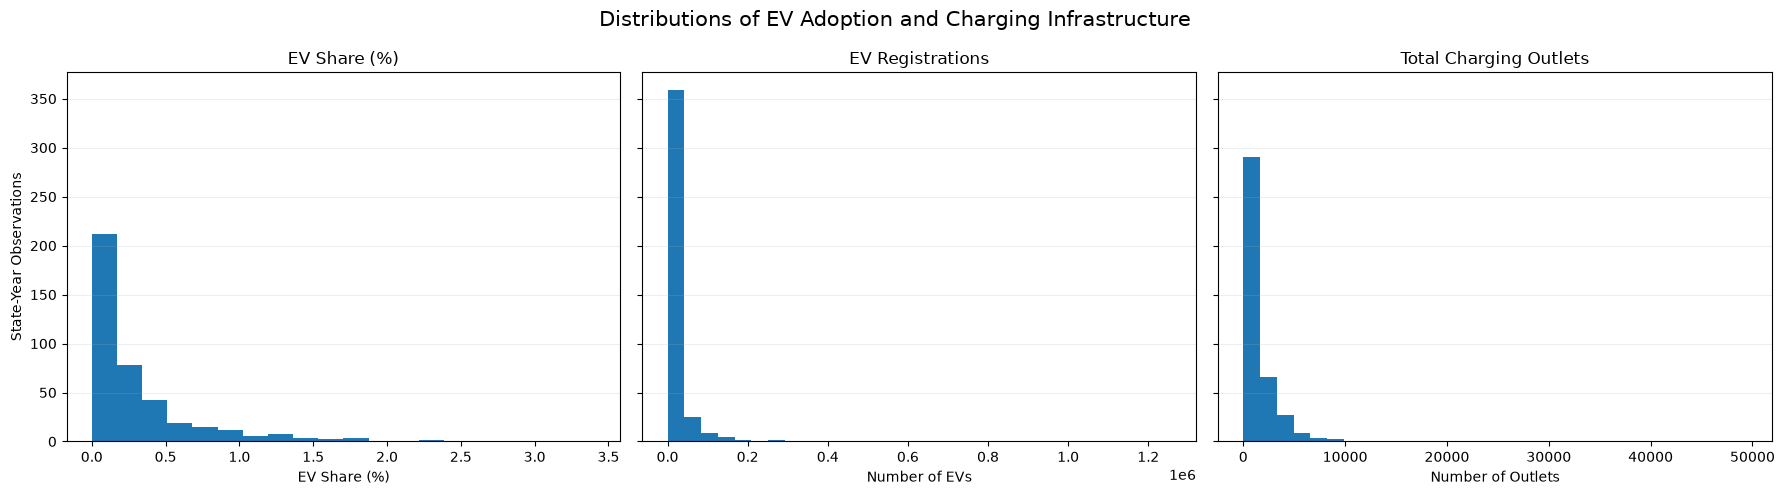

In [293]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# EV Share
axes[0].hist(df_eda["EV Share (%)"].dropna(), bins=20)
axes[0].set_title("EV Share (%)")
axes[0].set_xlabel("EV Share (%)")
axes[0].set_ylabel("State-Year Observations")
axes[0].grid(axis="y", alpha=0.2)

# EV Registrations
axes[1].hist(df_eda["EV Registrations"].dropna(), bins=30)
axes[1].set_title("EV Registrations")
axes[1].set_xlabel("Number of EVs")
axes[1].grid(axis="y", alpha=0.2)

# Total Charging Outlets
axes[2].hist(df_eda["Total Charging Outlets"].dropna(), bins=30)
axes[2].set_title("Total Charging Outlets")
axes[2].set_xlabel("Number of Outlets")
axes[2].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Distributions of EV Adoption and Charging Infrastructure",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Outlier Review Using the IQR Rule

We are simply checking for outliers within the dataset using interquartile range. We are doing this for observation purposes, not to automatically remove them. 

EV Registrations has 49 flagged outliers, indicating substantial variation. We can likely attribute this to some states having a substantially higher EV adoption than other states instead of an error. This goes for EV Share Percentage as well. 

The 31 flagged observations for Stations and 34 flags for Total Charging Outlets suggest that charging infrastructure may be concentrated more heavily in some state-year observations than others; this makes sense because of how states different in their charging infrastructure. 

48 flagged observations show noticeable variation in electricity prices across different states and years. 

The vast majority of the outliers in our data can be explained by organic differences between states and years as opposed to errors, and so these observations will be retained instead of removed. 

In [295]:
outlier_columns = [
    "EV Registrations", "EV Share (%)", "Stations",
    "Total Charging Outlets", "Per_Cap_Income",
    "price_cents_per_kwh", "gasoline_price_per_gallon"
]

outlier_rows = []
for col in outlier_columns:
    s = df_eda[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append([col, q1, q3, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=["Variable", "Q1", "Q3", "Lower Bound", "Upper Bound", "IQR Flags"]
).set_index("Variable")

outlier_summary.round(2)

,Q1,Q3,Lower Bound,Upper Bound,IQR Flags
Variable,,,,,
EV Registrations,1400.00,18000.00,-23500.00,42900.00,49
EV Share (%),0.06,0.41,-0.46,0.93,35
Stations,126.00,733.50,-785.25,1644.75,31
Total Charging Outlets,314.75,1897.00,-2058.62,4270.38,34
Per_Cap_Income,30897.25,39978.50,17275.38,53600.38,8
price_cents_per_kwh,9.08,12.33,4.20,17.20,48
gasoline_price_per_gallon,2.50,2.97,1.80,3.67,18


## 2. Feature-engineering measures explored during EDA

To better compare EV adoption and charging infrastructure across states of different sizes, EDA explores several normalized measures before the final feature-engineering step.

**Outlets per 100,000 people:** charging infrastructure availability relative to the working-age population.

**EVs per Charging Outlet:** the number of registered EVs relative to the number of public charging outlets, providing an indication of charging demand relative to available infrastructure.

 **Fast-Charger Share:** the percentage of total charging outlets that are DC Fast chargers, describing the composition of the charging network.

In [298]:
# Create three normalized infrastructure measures—outlets per 100,000 people, EVs per outlet, and fast-charger share—and calculate their annual median values.

df_eda["outlets_per_100k"] = (
    df_eda["Total Charging Outlets"] / df_eda["Population_20_64"] * 100000
)
df_eda["evs_per_outlet"] = (
    df_eda["EV Registrations"] / df_eda["Total Charging Outlets"]
)
df_eda["fast_charger_share"] = (
    df_eda["DC Fast"] / df_eda["Total Charging Outlets"] * 100
)

derived_annual = df_eda.groupby("year").agg(
    median_evs_per_outlet=("evs_per_outlet", "median"),
    median_outlets_per_100k=("outlets_per_100k", "median"),
    median_fast_charger_share=("fast_charger_share", "median"),
    mean_ev_share=("EV Share (%)", "mean")
)
derived_annual.round(2)

,median_evs_per_outlet,median_outlets_per_100k,median_fast_charger_share,mean_ev_share
year,,,,
2016,2.90,16.94,13.06,0.07
2017,3.80,20.62,12.58,0.09
2018,5.97,23.81,16.65,0.14
2019,6.46,30.19,16.16,0.19
2020,6.79,35.52,17.08,0.26
2021,8.61,43.17,18.12,0.37
2022,13.45,48.68,21.24,0.62
2023,15.01,66.77,24.18,0.90


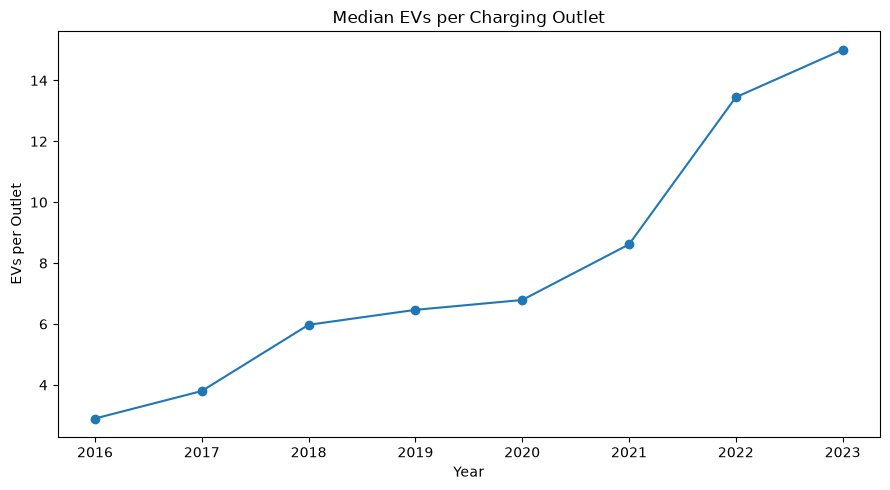

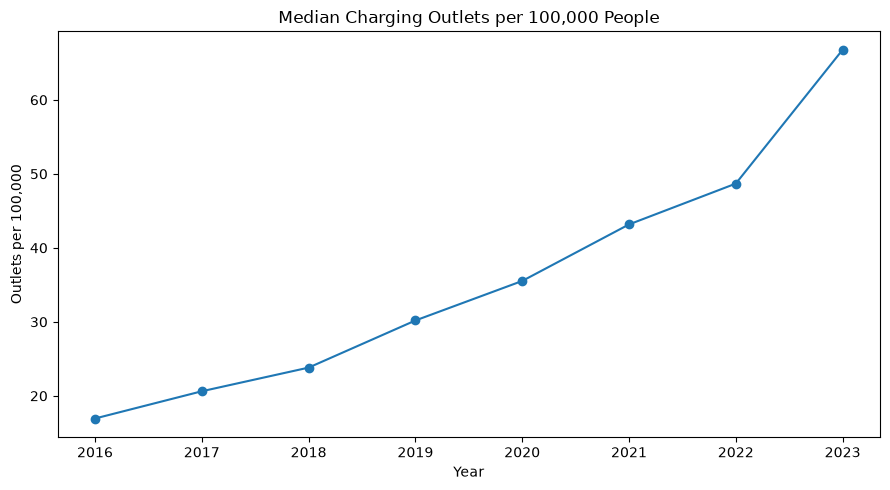

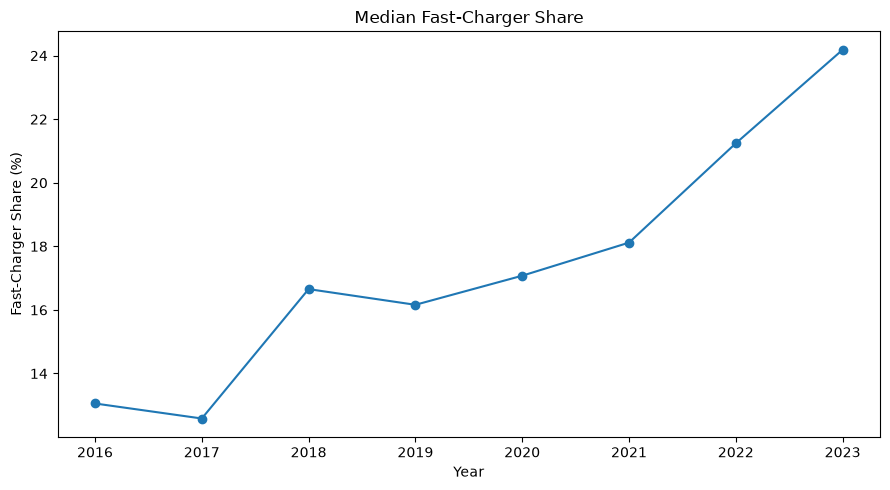

In [299]:
# Plot the annual medians of EVs per outlet, outlets per 100,000 people, and fast-charger share to compare infrastructure patterns across years.

figures = [
    ("Median EVs per Charging Outlet", "median_evs_per_outlet", "EVs per Outlet"),
    ("Median Charging Outlets per 100,000 People", "median_outlets_per_100k", "Outlets per 100,000"),
    ("Median Fast-Charger Share", "median_fast_charger_share", "Fast-Charger Share (%)")
]
for title, col, ylabel in figures:
    plt.figure(figsize=(9, 5))
    plt.plot(derived_annual.index, derived_annual[col], marker="o")
    plt.title(title)
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 4. Relationships with EV Share

Pearson correlations are used as descriptive screening tools. They do not establish causation. EV Registrations and Total Vehicles are excluded from candidate predictors because Step 1 established that they mathematically determine EV Share.

In [301]:
# Calculate Pearson correlations between EV Share and candidate infrastructure, economic, policy, demographic, and energy variables to identify relationships relevant to modelling.

candidate_columns = [
    "Stations", "Total Charging Outlets", "Level 1", "Level 2", "DC Fast",
    "fuel_economy", "Incentives", "Population_20_64",
    "Labour_Force_Participation_Rate", "Unemployment_Rate",
    "Bachelor_Attainment", "Per_Cap_Income",
    "price_cents_per_kwh", "gasoline_price_per_gallon",
    "outlets_per_100k", "evs_per_outlet", "fast_charger_share"
]

correlation_table = (
    df_eda[df_eda["year"] >= 2018][candidate_columns + ["EV Share (%)"]]
    .corr(numeric_only=True)["EV Share (%)"]
    .drop("EV Share (%)")
    .sort_values(ascending=False)
    .rename("Correlation with EV Share (%)")
    .to_frame()
)
correlation_table.round(3)

,Correlation with EV Share (%)
gasoline_price_per_gallon,0.774
outlets_per_100k,0.741
Per_Cap_Income,0.662
evs_per_outlet,0.615
DC Fast,0.584
Stations,0.582
Total Charging Outlets,0.560
Level 2,0.552
Incentives,0.498
Bachelor_Attainment,0.492


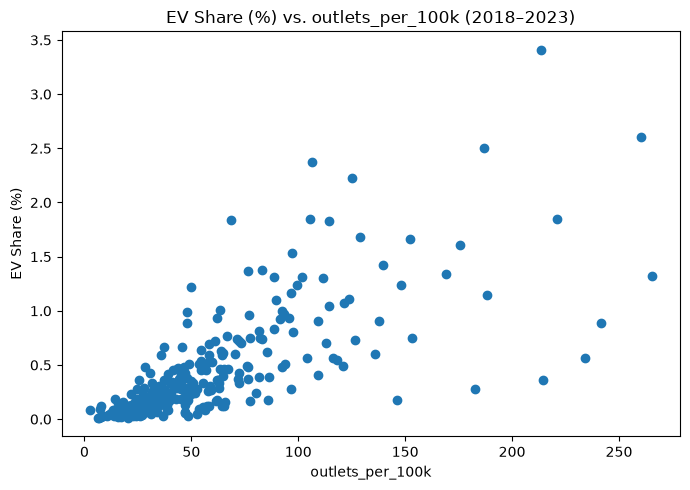

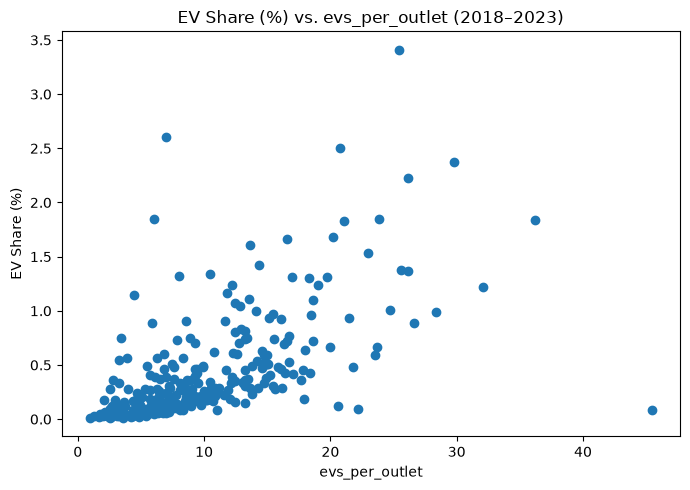

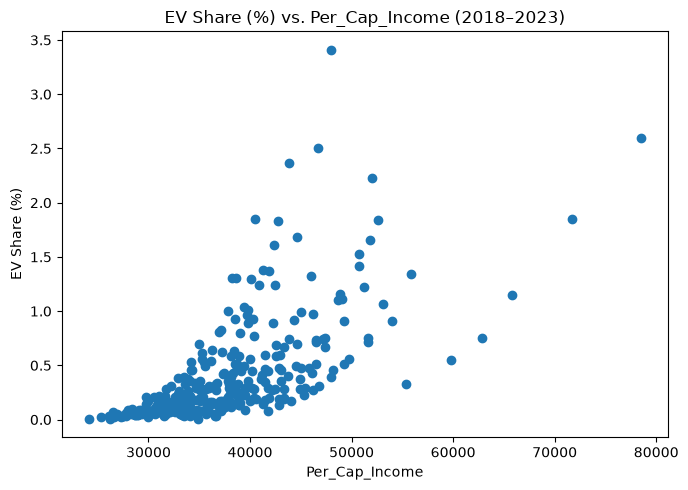

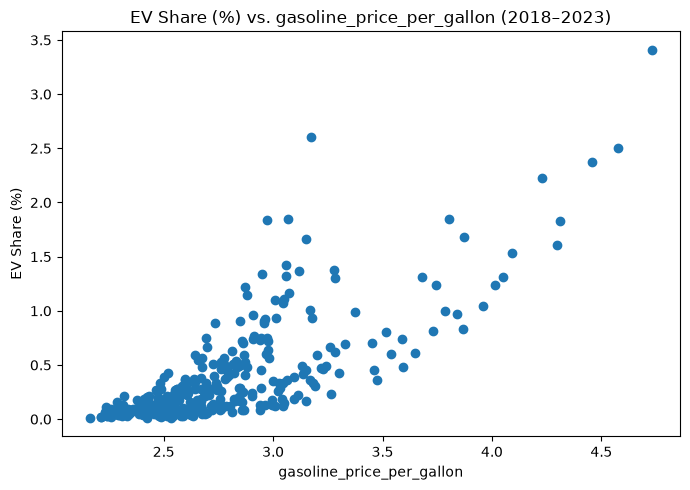

In [302]:
# Create scatterplots showing EV Share against outlets per 100,000 people, EVs per outlet, income, gasoline price, and fast-charger share for 2018–2023 observations.

relationship_pairs = [
    ("EV Share (%)", "outlets_per_100k"),
    ("EV Share (%)", "evs_per_outlet"),
    ("EV Share (%)", "Per_Cap_Income"),
    ("EV Share (%)", "gasoline_price_per_gallon")
]
for y_col, x_col in relationship_pairs:
    plt.figure(figsize=(7, 5))
    plt.scatter(df_eda.loc[df_eda["year"] >= 2018, x_col],
                df_eda.loc[df_eda["year"] >= 2018, y_col])
    plt.title(f"{y_col} vs. {x_col} (2018–2023)")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.tight_layout()
    plt.show()

## 5. Predictor multicollinearity review

This section examines correlations among candidate predictors rather than only their relationship with EV Share.

A particularly important diagnostic is the relationship between **Per_Cap_Income** and **Bachelor_Attainment**. Very high predictor-predictor correlation can make individual regression coefficients unstable or difficult to interpret.

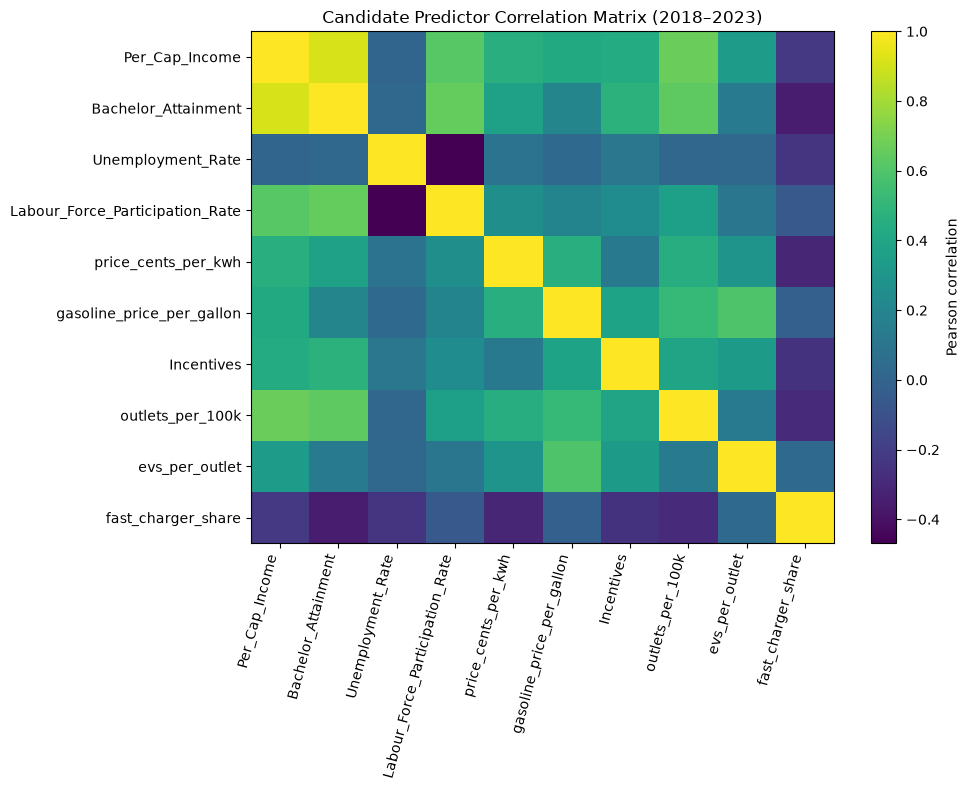

In [304]:
# Calculate the Pearson correlation matrix among the candidate modelling predictors for 2018–2023 to identify potentially redundant features.

predictor_columns = [
    "Per_Cap_Income", "Bachelor_Attainment", "Unemployment_Rate",
    "Labour_Force_Participation_Rate", "price_cents_per_kwh",
    "gasoline_price_per_gallon", "Incentives",
    "outlets_per_100k", "evs_per_outlet", "fast_charger_share"
]
predictor_corr = df_eda[df_eda["year"] >= 2018][predictor_columns].corr()

# Display the candidate-predictor correlation matrix as a heatmap-style image to make strong relationships among potential features easier to identify.

plt.figure(figsize=(10, 8))
plt.imshow(predictor_corr, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(predictor_columns)), predictor_columns, rotation=75, ha="right")
plt.yticks(range(len(predictor_columns)), predictor_columns)
plt.title("Candidate Predictor Correlation Matrix (2018–2023)")
plt.tight_layout()
plt.show()

## 6. Recheck charging-outlet consistency

Step 2 found that the component charging counts do not always exactly equal the reported total. This check carries that finding into EDA.

In [306]:
# Compare reported Total Charging Outlets with Level 1 + Level 2 + DC Fast and report the number, percentage, mean absolute size, and maximum size of mismatches.

outlet_difference = (
    df_eda["Total Charging Outlets"]
    - (df_eda["Level 1"] + df_eda["Level 2"] + df_eda["DC Fast"])
)

print("Rows with a non-zero outlet difference:", int((outlet_difference != 0).sum()))
print("Percent of rows with a mismatch:", round((outlet_difference != 0).mean() * 100, 2))
print("Mean absolute difference:", round(outlet_difference.abs().mean(), 2))
print("Maximum absolute difference:", int(outlet_difference.abs().max()))

mismatch_table = df_eda.loc[
    outlet_difference.abs().nlargest(10).index,
    ["state", "year", "Total Charging Outlets", "Level 1", "Level 2", "DC Fast"]
].copy()
mismatch_table["Outlet Difference"] = outlet_difference.loc[mismatch_table.index]
mismatch_table.sort_values("Outlet Difference", key=lambda s: s.abs(), ascending=False)

Rows with a non-zero outlet difference: 24
Percent of rows with a mismatch: 5.88
Mean absolute difference: 4.53
Maximum absolute difference: 1399


,state,year,Total Charging Outlets,Level 1,Level 2,DC Fast,Outlet Difference
367,Georgia,2016,1493,171,2303,418,-1399
259,California,2018,21166,641,17778,2657,90
310,California,2017,16111,854,13982,1196,79
208,California,2019,27199,532,22933,3661,73
157,California,2020,34924,498,28885,5497,44
106,California,2021,41237,648,33723,6824,42
55,California,2022,43589,559,34366,8634,30
4,California,2023,49433,648,38217,10548,20
73,Michigan,2022,2703,14,2153,526,10
124,Michigan,2021,1799,24,1373,392,10


## 7. National Charging Level Patterns

We look at how the different charging levels change nationally over the years.

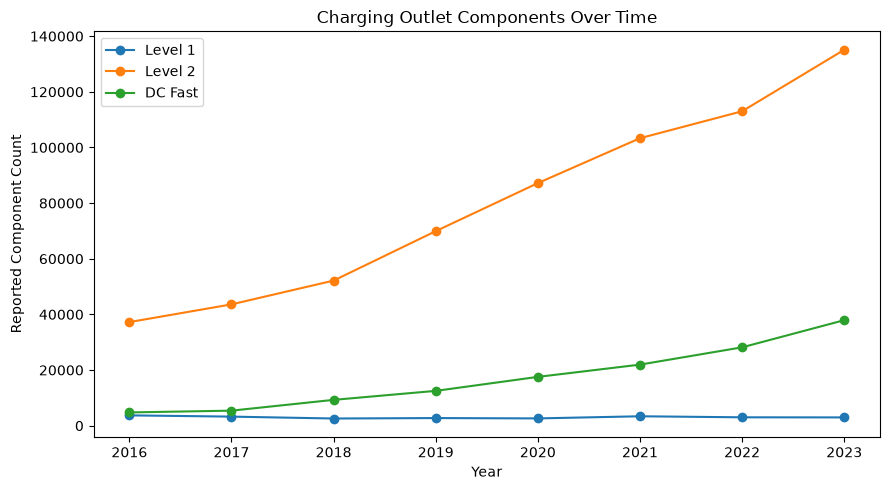

In [308]:
charging_annual = df_eda.groupby("year")[["Level 1", "Level 2", "DC Fast"]].sum()

plt.figure(figsize=(9, 5))
for col in ["Level 1", "Level 2", "DC Fast"]:
    plt.plot(charging_annual.index, charging_annual[col], marker="o", label=col)

plt.title("Charging Outlet Components Over Time")
plt.xlabel("Year")
plt.ylabel("Reported Component Count")
plt.legend()
plt.tight_layout()
plt.show()

Level 1: Wall Outlets 
Level 2: Everyday Home Charging, Workplaces, Public Parking Garages
DCA Fast: Commercial Power Stations


# Modeling

## Problem Statement

Building on the findings from the EDA, this notebook analyzes differences in EV adoption across U.S. states to identify factors associated with lower and higher EV adoption and provide insights that may inform areas for further attention.

We aim to help lower-EV-adoption states understand what factors may be associated with stronger EV adoption and where potential gaps exist.

The cleaned dataset produced in the Data Cleaning notebook is used as the input for modeling.

| Variable | Description |
|---|---|
| state | US state |
| year | Year of observation |
| EV Registrations | Number of electric vehicles registered in the state |
| Total Vehicles | Total number of registered vehicles in the state |
| EV Share (%) | Percentage of registered vehicles that are electric vehicles |
| Stations | Number of public EV charging stations |
| Total Charging Outlets | Total number of individual public charging outlets |
| Level 1 | Number of Level 1 charging outlets |
| Level 2 | Number of Level 2 charging outlets |
| DC Fast | Number of DC Fast charging outlets |
| Population_20_64 | Working-age population (ages 20–64) |
| Per_Cap_Income | Per-capita income in the state |
| Bachelor_Attainment | Percentage of the population with a bachelor's degree or higher |
| Labour_Force_Participation_Rate | Percentage of the working-age population participating in the labor force |
| Unemployment_Rate | Percentage of the labor force that is unemployed |
| price_cents_per_kwh | Average electricity price per kilowatt-hour, in cents |
| gasoline_price_per_gallon | Average gasoline price per gallon |
| Incentives | State-level EV incentives |
| Outlets_per_100k | Total public charging outlets per 100,000 working-age residents |
| fast_charger_share | Percentage of total charging outlets that are DC Fast outlets |
| EV_Growth | Year-over-year growth in EV registrations |
| High_EV_Growth | Binary indicator identifying states with above-median EV growth |
| Adoption_Group | Classification of states into high- or low-EV-adoption groups |
| Infrastructure_Gap_per_100k | Difference between observed charging outlets per 100,000 residents and the benchmark level |
| Priority_State | Indicator identifying states with high EV adoption, high EV growth, and a positive infrastructure gap |

In [312]:
import geopandas as gpd
import seaborn as sns

The modeling dataset consists of state-year observations from 2018–2023. The 2016–2017 observations were excluded from modeling because several potential predictor variables have substantial missingness for those years.

In [314]:
model_df = df_clean[df_clean["year"] >= 2018].copy()
print("Modeling dataset:", model_df.shape)


Modeling dataset: (306, 35)


In [315]:
model_df.head()

,state,year,EV Registrations,Total Vehicles,EV Share (%),Stations,Total Charging Outlets,Level 1,Level 2,DC Fast,...,reducetax,regulate,worried,price_cents_per_kwh,gasoline_price_per_gallon,Total,Trucks,Trucks_Share,Party,state_code
0,Alabama,2023,13000,4835900,0.27,424,1096,35,704,357,...,62.16,69.01,54.95,11.47,2.742,5446619.0,3.397137e+06,62.37,Republican,AL
1,Alaska,2023,2700,559800,0.48,65,124,3,87,34,...,65.38,71.61,62.49,21.41,3.594,680974.0,5.175250e+05,76.00,Republican,AK
2,Arizona,2023,89800,6529000,1.38,1198,3506,9,2478,1019,...,64.73,73.19,64.32,12.19,3.278,6447062.0,3.868118e+06,60.00,Democratic,AZ
3,Arkansas,2023,7100,2708300,0.26,334,833,3,709,121,...,63.39,68.58,56.21,9.73,2.760,3338322.0,2.291924e+06,68.65,Republican,AR
4,California,2023,1256600,36850300,3.41,16381,49433,648,38217,10548,...,72.08,76.30,71.24,24.87,4.731,31057329.0,1.675788e+07,53.96,Democratic,CA


In [316]:
# 51 states have 6 observations each

model_df.groupby("state").size().value_counts()

6    51
Name: count, dtype: int64

| Category | Potential Features|
|---|---|
| **Targets** | EV Registrations, EV Share (%), EV Share growth, Above-median growth |
| **Predictors** | Total Vehicles, Stations, Total Charging Outlets, Level 1, Level 2, DC Fast, fuel_economy, Incentives, Population_20_64, Education_Bachelor, Labour_Force_Participation_Rate, Unemployment_Rate, Bachelor_Attainment, Per_Cap_Income, price_cents_per_kwh, gasoline_price_per_gallon, Trucks, Trucks_Share |
| **Categorical** | Party, state |
| **Attitudes** | affectweather, devharm, discuss, exp, localofficials, personal, reducetax, regulate, worried |

### Descriptive analysis

In [319]:
# How much did EV Share change across states from 2018 to 2023?

state_ev_shares = model_df.pivot(
    index="state",
    columns="year",
    values="EV Share (%)"
).sort_index()

state_ev_shares["change_2018_2023"] = (
    state_ev_shares[2023] - state_ev_shares[2018]
)

state_changes = (
    state_ev_shares[["change_2018_2023"]]
    .reset_index()
)

# Reuse the state codes created during data preparation.
state_changes["STUSPS"] = state_changes["state"].map(state_codes)


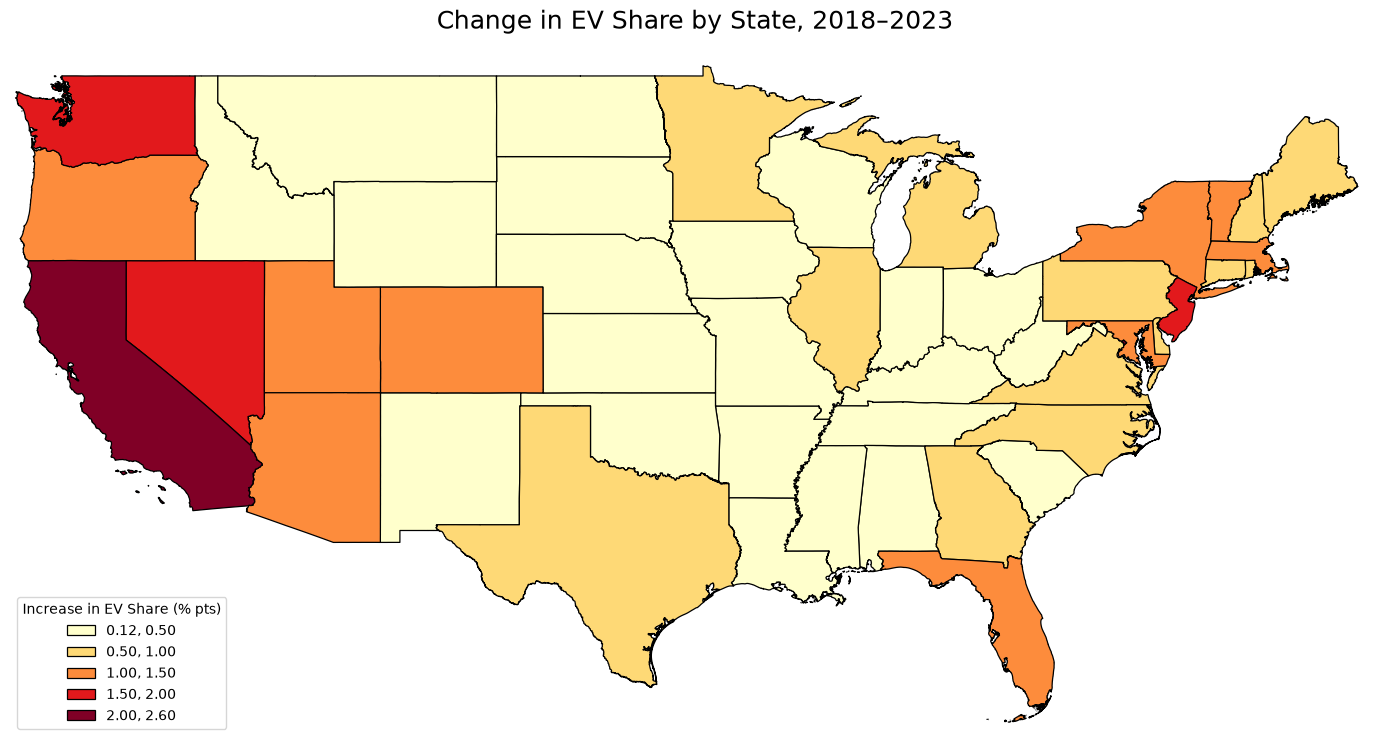

In [320]:
#%pip install mapclassify

try:
    url = "https://www2.census.gov/geo/tiger/GENZ2022/shp/cb_2022_us_state_500k.zip"
    states = gpd.read_file(url)

    map_data = states.merge(state_changes, on="STUSPS", how="left")

    fig, ax = plt.subplots(figsize=(14, 8))

    map_data.plot(
        column="change_2018_2023", cmap="YlOrRd", scheme="UserDefined",
        classification_kwds={"bins": [0.5, 1.0, 1.5, 2.0, 2.6]},
        linewidth=0.9, edgecolor="black", legend=True, ax=ax,
        legend_kwds={"title": "Increase in EV Share (% pts)", "loc": "lower left"}
    )

    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.set_title("Change in EV Share by State, 2018–2023", fontsize=18, pad=15)
    ax.axis("off")
    plt.tight_layout()
    plt.show()
except Exception as e:
     print("Map could not be generated:", e)
   

EV Share increased across states between 2018 and 2023, with substantial variation in the magnitude of change.

The descriptive analysis shows that EV adoption increased over time and that the magnitude of adoption differed across states. We therefore investigated whether measurable state characteristics were associated with EV Share

## 1. Regression Model

In [323]:
#%pip install statsmodels

In [324]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [482]:
# Create infrastructure features
model_df["outlets_per_100k"] = (
    model_df["Total Charging Outlets"] / model_df["Population_20_64"] * 100000
)

# Handle missing DC incentive values

model_df.loc[
    (model_df["state"] == "District Of Columbia") &
    (model_df["Incentives"].isna()),
    "Incentives"
] = 0

The Incentives variable contained six missing observations, all corresponding to the District of Columbia. Because these observations represent the absence of reported incentives rather than an unknown value, they were coded as 0

In [327]:
# Can EV Share be predicted from infrastructure, economic, policy, and environmental-attitude factors?
attitude_features = [
    "affectweather", "devharm", "discuss", "exp", "localofficials",
    "personal", "reducetax", "regulate", "worried", "Incentives"
]

attitude_corr = model_df[attitude_features + ["EV Share (%)"]].corr()

attitude_corr["EV Share (%)"].sort_values(ascending=False).round(2)

EV Share (%)      1.00
devharm           0.64
exp               0.63
personal          0.62
worried           0.54
affectweather     0.53
discuss           0.46
reducetax         0.44
Incentives        0.42
localofficials    0.40
regulate          0.32
Name: EV Share (%), dtype: float64

The attitude variables showed relatively weak associations with EV Share, so they were not equally emphasized in the subsequent analysis.

### Feature Selection

#### Candidate Features

Candidate features were selected based on their relevance to EV adoption, findings from EDA, and data quality. Variables that were redundant with the target or could introduce data leakage were excluded.


In [331]:
candidate_features = [
    "gasoline_price_per_gallon", "price_cents_per_kwh", "Per_Cap_Income",
    "outlets_per_100k", "Incentives",
    "fuel_economy", "Bachelor_Attainment", "affectweather", "devharm",
    "discuss", "exp", "localofficials", "personal", "reducetax",
    "regulate", "worried"
]

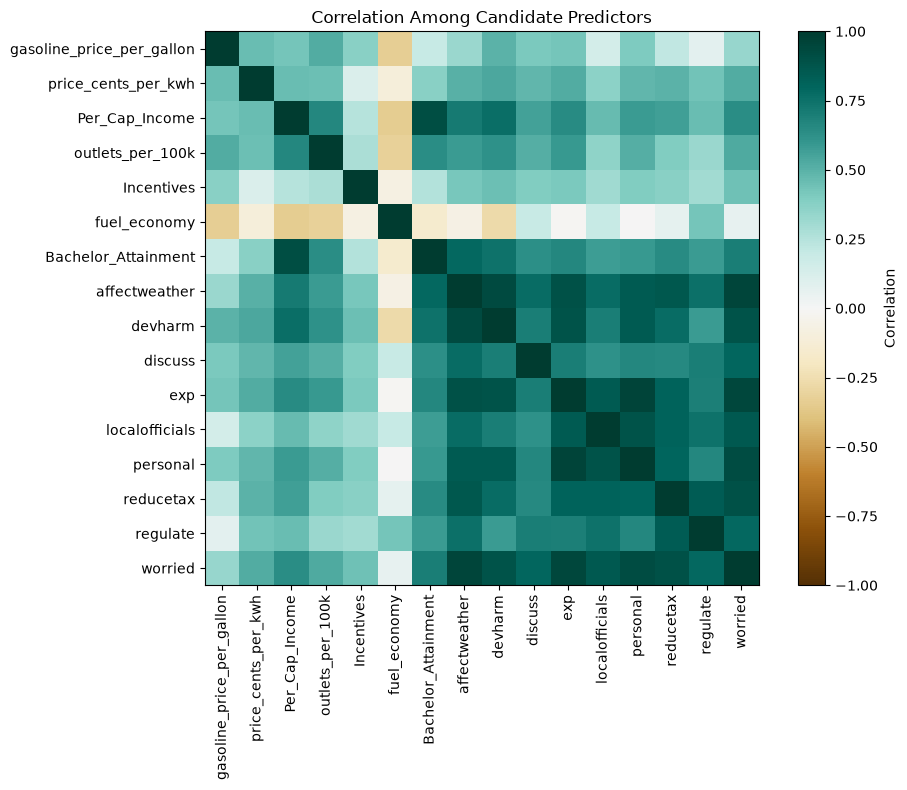

In [332]:
correlation_matrix = model_df[candidate_features].corr()

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap="BrBG", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(candidate_features)), candidate_features, rotation=90)
plt.yticks(range(len(candidate_features)), candidate_features)
plt.title("Correlation Among Candidate Predictors")
plt.tight_layout()
plt.show()

#### Check Multicollinearity with VIF

Variance Inflation Factor (VIF) was used to assess multicollinearity among the candidate predictors. High VIF values indicate that a predictor has substantial overlap with other predictors, which can make regression coefficients less stable.

In [334]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = model_df[candidate_features].dropna()

vif = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).sort_values("VIF", ascending=False)

vif

,Feature,VIF
15,worried,38.597569
10,exp,24.980091
12,personal,24.687098
7,affectweather,24.636346
8,devharm,16.510889
6,Bachelor_Attainment,15.864453
2,Per_Cap_Income,13.250381
13,reducetax,10.134629
14,regulate,9.421012
11,localofficials,8.874281


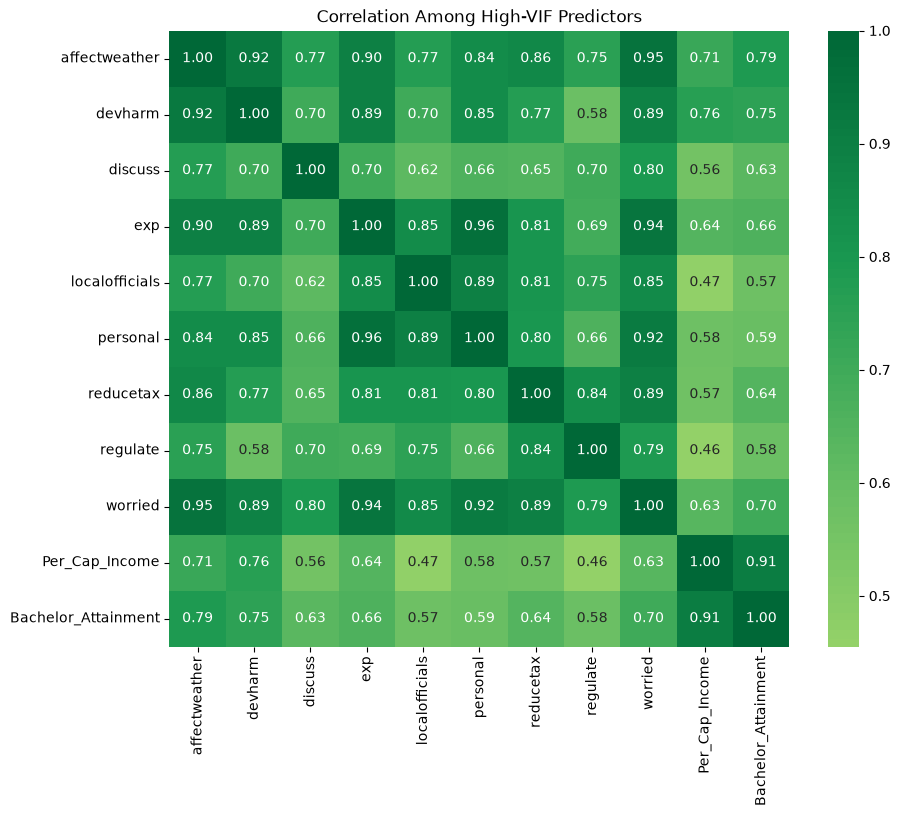

In [335]:
high_vif_features = [
    "affectweather", "devharm", "discuss", "exp", "localofficials",
    "personal", "reducetax", "regulate", "worried",
    "Per_Cap_Income", "Bachelor_Attainment"
]

plt.figure(figsize=(10, 8))

high_vif_corr = model_df[high_vif_features].corr()

sns.heatmap(
    high_vif_corr, annot=True, fmt=".2f",
    cmap="RdYlGn", center=0
)
plt.title("Correlation Among High-VIF Predictors")
plt.show()


#### Reduce the feature set

Per-capita income was highly correlated with several other predictors, including environmental-attitude measures and Bachelor Attainment. Including it alongside those variables created substantial multicollinearity. We therefore excluded it from the candidate predictor set to reduce redundancy and make the individual predictor relationships more interpretable.

After reducing the feature set, VIF was recalculated to confirm that multicollinearity was reduced before proceeding to regression modeling.

In [338]:
reduced_features = [ "outlets_per_100k", "gasoline_price_per_gallon", "Incentives", "devharm",
                      "exp", "reducetax", "regulate"]

In [339]:
X_reduced = model_df[reduced_features].dropna()

vif_reduced = pd.DataFrame({
    "Feature": X_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_reduced.values, i)
        for i in range(X_reduced.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_reduced

,Feature,VIF
4,exp,6.613922
3,devharm,6.279141
5,reducetax,5.924571
6,regulate,3.763430
0,outlets_per_100k,1.895019
1,gasoline_price_per_gallon,1.708242
2,Incentives,1.329900


In [340]:
train_df = model_df[model_df["year"] <= 2021].copy()
test_df = model_df[model_df["year"] >= 2022].copy()

X_train = train_df[reduced_features].copy()
y_train = train_df["EV Share (%)"]

X_test = test_df[reduced_features].copy()
y_test = test_df["EV Share (%)"]

print("\nTrain rows:", len(X_train))
print("Test rows:", len(X_test))


Train rows: 204
Test rows: 102


## Baseline Linear Regression

A linear regression model was first used as a baseline to evaluate whether the candidate predictors had approximately linear relationships with EV Share.


Linear Regression
R²: 0.3917
RMSE: 0.4893


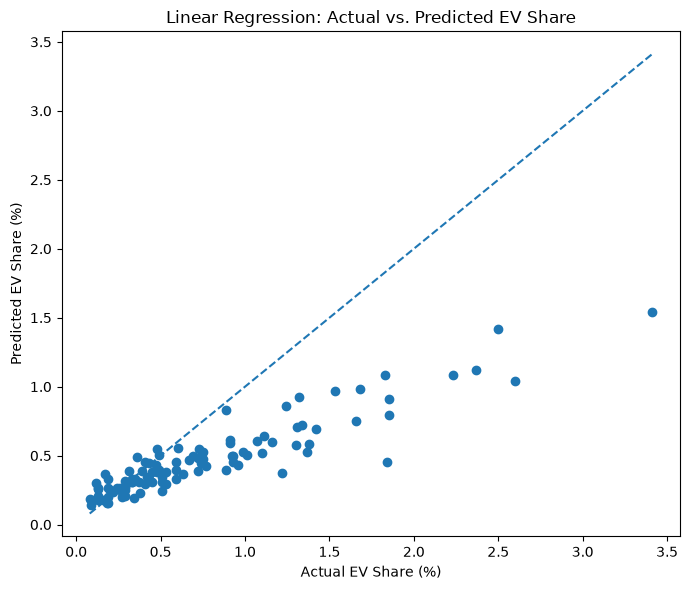

In [342]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_r2 = r2_score(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))

print("\nLinear Regression")
print("R²:", round(linear_r2, 4))
print("RMSE:", round(linear_rmse, 4))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_linear)

plt.plot(

    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual EV Share (%)")
plt.ylabel("Predicted EV Share (%)")
plt.title("Linear Regression: Actual vs. Predicted EV Share")
plt.tight_layout()
plt.show()

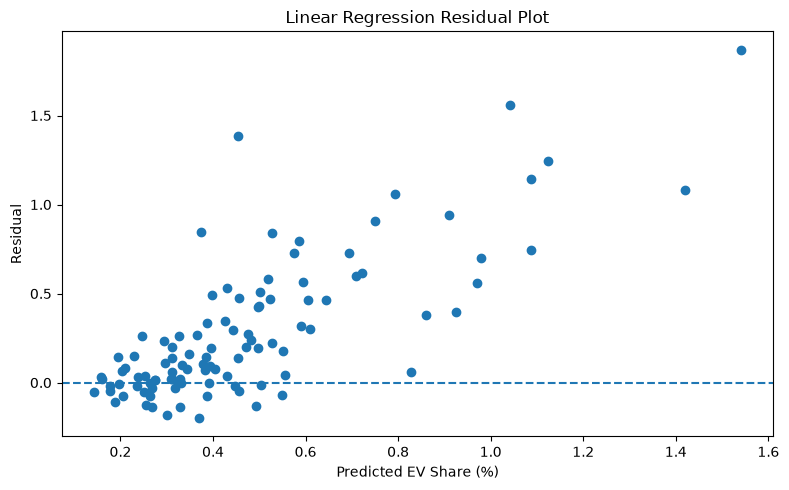

In [343]:
linear_residuals = y_test - y_pred_linear

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_linear, linear_residuals)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted EV Share (%)")
plt.ylabel("Residual")
plt.title("Linear Regression Residual Plot")
plt.tight_layout()
plt.show()

The residuals plot shows that the linear model tends to underpredict states with higher EV Share. This suggests that the linear model may not fully capture the relationship between the predictors and EV Share, motivating the evaluation of a nonlinear model.

## Model Comparison

Because the data contain repeated observations for each state over time, persistent state differences and broader time trends could also contribute to the pattern. We therefore compared models that included state and year alongside the selected predictors.

In [346]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

target = "EV Share (%)"

model_data = model_df[["state", "year", target] + reduced_features].dropna(subset=[target, "state", "year"]).copy()
train_df = model_data[model_data["year"] <= 2021].copy()
test_df = model_data[model_data["year"] >= 2022].copy()

numeric_features = reduced_features + ["year"]
state_feature = ["state"]

spline_features = [f for f in ["outlets_per_100k", "gasoline_price_per_gallon"] if f in reduced_features]
linear_features = [f for f in numeric_features if f not in spline_features]

alpha_values = np.logspace(-4, 2, 30)

# Selects which columns get applied with the steps
linear_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("state", OneHotEncoder(drop="first", handle_unknown="ignore"), state_feature),
])

spline_preprocessor = ColumnTransformer([
    ("splines", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("spline", SplineTransformer(n_knots=3, degree=2, include_bias=False, extrapolation="linear")),
    ]), spline_features),
    ("other_numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), linear_features),
    ("state", OneHotEncoder(drop="first", handle_unknown="ignore"), state_feature),
])

forest_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("state", OneHotEncoder(handle_unknown="ignore"), state_feature),
])

models = {
    "Linear Ridge": Pipeline([
        ("prep", linear_preprocessor),
        ("model", RidgeCV(alphas=alpha_values, cv=5, scoring="neg_mean_squared_error")),
    ]),
    "Spline Ridge": Pipeline([
        ("prep", spline_preprocessor),
        ("model", RidgeCV(alphas=alpha_values, cv=5, scoring="neg_mean_squared_error")),
    ]),
    "Random Forest": Pipeline([
        ("prep", forest_preprocessor),
        ("model", RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=8, random_state=42)),
    ]),
}

X_train = train_df[["state", "year"] + reduced_features]
y_train = train_df[target]
X_test = test_df[["state", "year"] + reduced_features]
y_test = test_df[target]

results = []

for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    train_pred = estimator.predict(X_train)
    test_pred = estimator.predict(X_test)
    results.append({
        "Model": name,
        "Train R²": r2_score(y_train, train_pred),
        "Test R²": r2_score(y_test, test_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
    })

print("Selected alphas:")
print("Linear Ridge:", models["Linear Ridge"].named_steps["model"].alpha_)
print("Spline Ridge:", models["Spline Ridge"].named_steps["model"].alpha_)

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

Selected alphas:
Linear Ridge: 0.004520353656360241
Spline Ridge: 0.007278953843983146


,Train R²,Test R²,Test MSE,Test RMSE
Model,,,,
Linear Ridge,0.9778,0.7757,0.0883,0.2971
Spline Ridge,0.9843,0.7500,0.0984,0.3137
Random Forest,0.8609,0.1868,0.3201,0.5658


Linear Ridge explains approximately 77.6% of the variation in EV Share test data and has the lowest test error among the models compared. 

Spline Ridge performed slightly worse, with a test R² of 0.750 and RMSE of 0.3137. Although it allowed selected predictors to have nonlinear relationships, this additional flexibility did not help much.

The gap between Linear Ridge’s train R² (0.978) and test R² (0.776) suggests some overfitting or a change between earlier and later years. However, its test performance remains substantially better than the Spline Ridge and Random Forest alternatives.

## Selected Model: Ridge Regression

In [349]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Use the fitted Linear Ridge pipeline from the previous comparison
ridge_model = models["Linear Ridge"]

# Raw test inputs expected by the pipeline
X_test_imp = test_df[["state", "year"] + reduced_features].copy()
y_test_imp = test_df["EV Share (%)"]

baseline_r2 = r2_score(y_test_imp, ridge_model.predict(X_test_imp))

rng = np.random.default_rng(42)
importance_rows = []

for feature in reduced_features:
    r2_drops = []

    for _ in range(30):
        X_permuted = X_test_imp.copy()

        # Shuffle this predictor across states separately within each test year
        # We are shuffling the predictors to identify key features by seeing
        # how much worse the model's performance is if we scramble the values.
        # Since year strongly affect the EV share, we want to see if a feature 
        # is no longer connected to exact state, will it change the performacnce?
        for _, row_indices in X_permuted.groupby("year").groups.items():
            X_permuted.loc[row_indices, feature] = rng.permutation(
                X_permuted.loc[row_indices, feature].to_numpy()
            )

        permuted_r2 = r2_score(
            y_test_imp,
            ridge_model.predict(X_permuted)
        )
        r2_drops.append(baseline_r2 - permuted_r2)

    importance_rows.append({
        "Feature": feature,
        "Mean R² decrease": np.mean(r2_drops),
        "Std. deviation": np.std(r2_drops),
    })

importance_df = (
    pd.DataFrame(importance_rows)
    .sort_values("Mean R² decrease", ascending=False)
)

importance_df.round(4)

,Feature,Mean R² decrease,Std. deviation
1,gasoline_price_per_gallon,0.7345,0.0893
0,outlets_per_100k,0.3762,0.0348
6,regulate,0.1896,0.0242
2,Incentives,0.0309,0.0048
4,exp,-0.0140,0.0023
5,reducetax,-0.0218,0.0031
3,devharm,-0.0593,0.0112


Permutation importance for the Linear Ridge model identified gasoline price and charging outlets per 100,000 people as the strongest contributors to held-out predictions.

Shuffling either variable reduced test R^2
by approximately 0.27.

The regulate, exp, and Incentives predictors had smaller contributions, while reducetax contributed little. Shuffling devharm slightly improved the score, suggesting it added little unique predictive value in this test. These are predictive associations, not evidence of causal effects.

## 2. Classification Model


After looking at EV adoption levels and the relationship between EV adoption and charging infrastructure, we were interested
in whether we can **predict whether a state will experience above-median EV adoption growth**. This is useful from a decision-making perspective because policymakers may want to understand comparative state growth.

For this analysis, we define **above-median** growth as a state whose EV Share increased more than the median growth across states for the relevant year. This gives us a relative measure of which states are growing faster versus slower than their peers.

In [354]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

#### Creating the Growth Measure

We first sorted the data by state and year because we needed to compare each state’s EV Share with its EV Share in the following year.

To determine whether a state experienced higher or lower EV growth, we first needed to measure how much its EV adoption changed from one year to the next. We then used groupby("state") and shift(-1) to obtain each state’s next-year EV Share.

Because our goal is to predict next-year EV adoption growth, we needed to align each year’s current EV Share with the following year’s EV Share. We sorted by state and year and used shift(-1) to bring the next year’s EV Share onto the current year’s row. We could then calculate next-year growth as next year’s EV Share minus the current year’s EV Share.

This also means that 2023 cannot be used to calculate a growth target, because we don’t have 2024 EV Share in our dataset. After the shift, the 2023 observations have no next-year value, so we remove those rows.

In [357]:
# using model_df

# Sorting the data by state and year
df_class = model_df.sort_values(["state", "year"]).copy()

# We are getting each state's EV Share for the following year
df_class["Next_Year_EV_Share"] = (
    df_class.groupby("state")["EV Share (%)"].shift(-1)
)

# Calculating the change in EV Share from current year to the next year
# The EV Growth is also right-skewed, so median growth in year is good.
df_class["EV_Share_Change"] = (
    df_class["Next_Year_EV_Share"] - df_class["EV Share (%)"]
)

# df_class[
#     ["state", "year", "EV Share (%)",
#      "Next_Year_EV_Share", "EV_Share_Change"]
# ].head(10)

### Creating the Classification Target

In this step, we convert the next-year EV Share growth into two classes for classification.

We then classified each state based on whether its EV Share growth was above or below the median growth of all states in the same year:

* 1 = Higher EV Growth: growth was above the same-year median.
* 0 = Lower EV Growth: growth was at or below the same-year median.

We used the same-year median because our goal was to identify states growing relatively faster or slower than their peers, while accounting for the fact that EV growth changes over time.

In [359]:
# We are removing rows where next year EV Share is unavailable
df_class = df_class.dropna(subset=["EV_Share_Change"]).copy()

In [360]:
# outlets per 100k is built once on the full table
df_class["Outlets_per_100k"] = (
    df_class["Total Charging Outlets"]
    / df_class["Population_20_64"]
) * 100000

rw_features = [
    "EV Share (%)",
    "Outlets_per_100k",
    "Per_Cap_Income",
    "Bachelor_Attainment",
    "Unemployment_Rate",
    "price_cents_per_kwh",
    "gasoline_price_per_gallon"
]

In [361]:
# High growth = above the median change of all states IN THE SAME YEAR
df_class["High_EV_Growth"] = (
    df_class["EV_Share_Change"]
    > df_class.groupby("year")["EV_Share_Change"].transform("median")
).astype(int)

# features are now measured relative to that year's average across states.
features = []
for f in rw_features:
    new_col = f + " (vs yr avg)"
    df_class[new_col] = df_class[f] - df_class.groupby("year")[f].transform("mean")
    features.append(new_col)

# Split by time
train_data = df_class[df_class["year"] <= 2021].copy()
test_data = df_class[df_class["year"] == 2022].copy()

print("Training rows:", train_data.shape[0])
print("Testing rows:", test_data.shape[0])

print("\nTraining years:", sorted(train_data["year"].unique()))
print("Testing years:", sorted(test_data["year"].unique()))

Training rows: 204
Testing rows: 51

Training years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]
Testing years: [np.int64(2022)]


In [362]:
# Predictor variables
X_train = train_data[features]
X_test = test_data[features]

# Target variable
y_train = train_data["High_EV_Growth"]
y_test = test_data["High_EV_Growth"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (204, 7)
X_test shape: (51, 7)
y_train shape: (204,)
y_test shape: (51,)


### Scaling the Features

Our features have different units and ranges, such as income in thousands of dollars and EV Share in percentages. `StandardScaler` puts these features on a similar scale so that their different numerical ranges do not unnecessarily affect the Logistic Regression model.

The scaler learns the mean and standard deviation from the training data and uses the same values to transform the test data.

In [364]:
from sklearn.preprocessing import StandardScaler

# Now creating the scaler
scaler = StandardScaler()

# Learning the scaling from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Using the SAME scaling on test data
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (204, 7)
Testing data scaled: (51, 7)


### Training the Logistic Regression Model

We use Logistic Regression to predict whether a state will have higher EV growth (1) or lower EV growth (0) in the following year.

The model learns the relationship between the selected features and the binary growth outcome using the training data. It then applies those learned relationships to the test data to predict whether each state has higher or lower EV growth.

In [366]:
from sklearn.linear_model import LogisticRegression

# Now create the Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# then training the model
log_model.fit(X_train_scaled, y_train)

# and predict the test data
y_pred = log_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
[0 0 1 0 1 1 1 1 1 1 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0
 1 0 1 0 0 0 0 1 1 1 1 0 0 0]


## Model Evaluation

### Confusion Matrix

The confusion matrix shows how many lower-growth and higher-growth states were classified correctly or incorrectly by the Logistic Regression model.

- **True Positive:** Higher-growth state correctly predicted as higher growth.
- **True Negative:** Lower-growth state correctly predicted as lower growth.
- **False Positive:** Lower-growth state incorrectly predicted as higher growth.
- **False Negative:** Higher-growth state incorrectly predicted as lower growth.

**Accuracy:** Measures how many total predictions were correct.

**Precision:** Of the states predicted to have higher EV growth, how many actually had higher growth.

**Recall:** Of the states that actually had higher EV growth, how many were correctly identified by the model.

**F1-score:** Balances Precision and Recall into a single evaluation measure.


Accuracy: 0.922
Precision (macro): 0.933
Recall (macro): 0.92
F1 Score (macro): 0.921


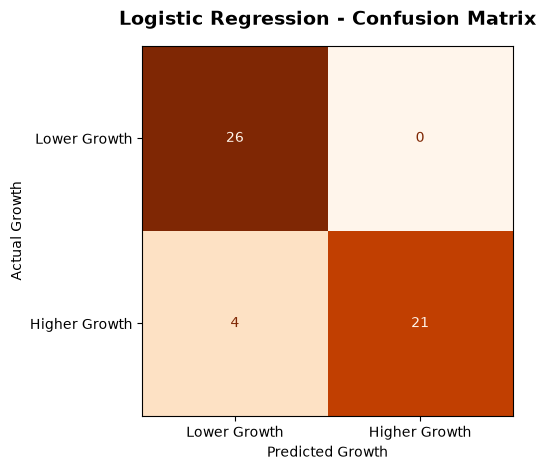

In [369]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print("Accuracy:", round(accuracy, 3))
print("Precision (macro):", round(precision, 3))
print("Recall (macro):", round(recall, 3))
print("F1 Score (macro):", round(f1, 3))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lower Growth", "Higher Growth"]
)

disp.plot(cmap="Oranges", colorbar=False)

plt.title("Logistic Regression - Confusion Matrix", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Growth")
plt.ylabel("Actual Growth")
plt.tight_layout()
plt.show()

The Logistic Regression model achieved 92.2% accuracy, 93.3% macro precision, 92.0% macro recall, and 92.1% macro F1-score.

Since we prioritize recall, the confusion matrix is particularly important. The model correctly identified 21 of the 25 higher-growth states, giving a higher-growth recall of 84%. It missed 4 higher-growth states (false negatives).

### Baseline Comparison Interpretation


In [372]:
import numpy as np

# baseline = predict the most common class in the TRAINING data.
majority_class = y_train.mode()[0]
baseline_pred = np.full(len(y_test), majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
#zero_division=0 avoids a warning if the baseline never predicts class 1
baseline_precision = precision_score(y_test, baseline_pred, zero_division=0)
baseline_recall = recall_score(y_test, baseline_pred, zero_division=0)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("Baseline Accuracy:", round(baseline_accuracy, 3))
print("Baseline Precision:", round(baseline_precision, 3))
print("Baseline Recall:", round(baseline_recall, 3))
print("Baseline F1 Score:", round(baseline_f1, 3))

print("\nLogistic Regression Accuracy:", round(accuracy, 3))
print("Logistic Regression Precision:", round(precision, 3))
print("Logistic Regression Recall:", round(recall, 3))
print("Logistic Regression F1 Score:", round(f1, 3))

Baseline Accuracy: 0.51
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1 Score: 0.0

Logistic Regression Accuracy: 0.922
Logistic Regression Precision: 0.933
Logistic Regression Recall: 0.92
Logistic Regression F1 Score: 0.921


This shows a substantial improvement over the baseline. Most importantly, the Logistic Regression model successfully identifies higher-growth states, while the baseline provides essentially no useful classification of the target class. This supports using Logistic Regression rather than relying on the baseline prediction.

### Logistic Regression Feature Coefficients

The coefficients show how each predictor is associated with the model's prediction of higher EV-adoption growth.

A positive coefficient is associated with a higher predicted probability of higher EV growth, while a negative coefficient is associated with a lower predicted probability.

Because the predictors were standardized before training, their coefficient magnitudes can be compared more meaningfully. These relationships represent model associations and should not be interpreted as causal effects.

In [375]:
import pandas as pd

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": log_model.coef_[0]
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print(coefficients)

                                 Feature  Coefficient  Absolute_Coefficient
0               EV Share (%) (vs yr avg)     3.077082              3.077082
3        Bachelor_Attainment (vs yr avg)     1.065214              1.065214
2             Per_Cap_Income (vs yr avg)     0.967140              0.967140
1           Outlets_per_100k (vs yr avg)     0.775544              0.775544
4          Unemployment_Rate (vs yr avg)     0.649739              0.649739
5        price_cents_per_kwh (vs yr avg)    -0.640563              0.640563
6  gasoline_price_per_gallon (vs yr avg)    -0.140452              0.140452


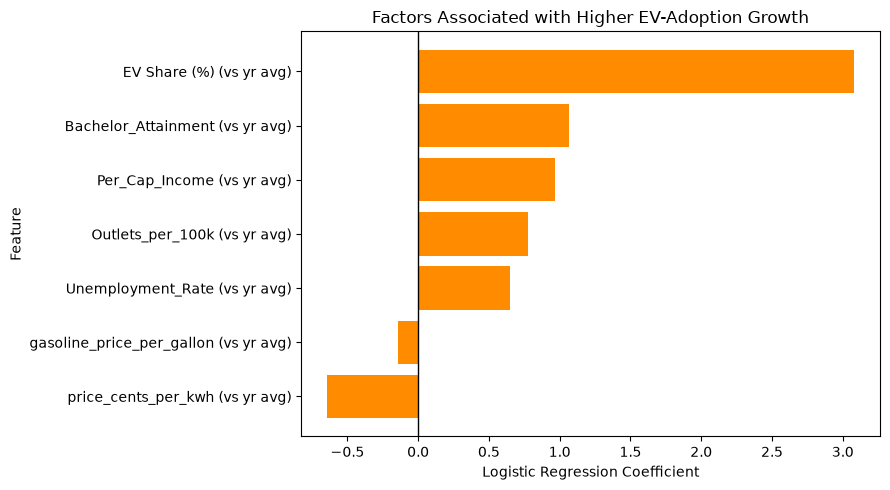

In [376]:
# Sorting coefficients for visualization
coef_plot = coefficients.sort_values("Coefficient")

plt.figure(figsize=(9, 5))

plt.barh(
    coef_plot["Feature"],
    coef_plot["Coefficient"],
    color="darkorange"
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Factors Associated with Higher EV-Adoption Growth")

plt.tight_layout()
plt.show()

### ROC Curve and AUC

The ROC curve evaluates how well the Logistic Regression model distinguishes between **Higher EV Growth** and **Lower EV Growth** across different classification thresholds.

Unlike the confusion matrix, which evaluates predictions at a single threshold, the ROC curve considers multiple thresholds by comparing the **True Positive Rate** with the **False Positive Rate**.

The **(AUC)** summarizes the model's overall ability to distinguish between the two classes. An AUC of 0.5 represents performance similar to random classification, while higher values indicate better discrimination.

A ROC-AUC of 0.997 indicates excellent discrimination. The model is extremely effective at distinguishing higher-growth states from lower-growth states across different classification thresholds.

ROC-AUC Score: 0.997


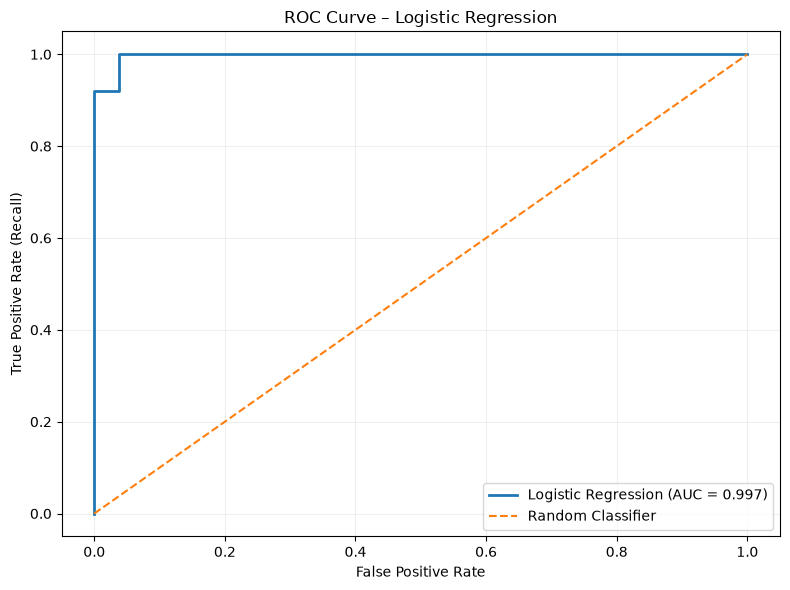

In [379]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(auc_score, 3))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve – Logistic Regression")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Calculate the infrastructure gap

Our model identifies charging infrastructure as an important predictor of EV adoption. We therefore examine whether high-adoption, high-growth states have charging infrastructure below their high-adoption peers. We quantify the infrastructure gap and examine the types of charging infrastructure contributing to it.

This identifies potential infrastructure gaps, not causal effects or exact infrastructure demand. County-level data and demand forecasting would be needed to determine where and how much additional infrastructure is required.

### Research Questions

This analysis focuses on four main questions:

1. How has EV adoption changed across U.S. states over time?
2. Which economic, demographic, energy-price, and charging-infrastructure factors are associated with EV adoption?
3. Can state-level characteristics be used to predict EV adoption and relatively high EV growth?
4. Is charging infrastructure keeping pace with EV adoption, and which states show potential infrastructure gaps?

In [381]:
states_2023 = model_df.loc[
    model_df["year"].eq(2023),
    [
        "state",
        "EV Share (%)",
        "EV Registrations",
        "Total Vehicles",
        "Total Charging Outlets",
        "Level 1",
        "Level 2",
        "DC Fast",
        "Population_20_64",
    ],
].copy()

states_2023["EVs_per_Outlet"] = (
    states_2023["EV Registrations"]
    / states_2023["Total Charging Outlets"]
)

states_2023["Outlets_per_100k"] = (
    states_2023["Total Charging Outlets"]
    / states_2023["Population_20_64"]
    * 100_000
)

growth_2022 = df_class.loc[
    df_class["year"].eq(2022),
    ["state", "EV_Share_Change", "High_EV_Growth"],
]

state_analysis = states_2023.merge(
    growth_2022,
    on="state",
    how="inner",
    validate="one_to_one",
)

# Reuse the Q1 definitions for the Q2 benchmark and priority-state comparison.
state_analysis["High_Adoption"] = (
    state_analysis["EV Share (%)"] >= state_analysis["EV Share (%)"].median()
)
state_analysis["Below_National_Infrastructure"] = (
    state_analysis["Outlets_per_100k"] < state_analysis["Outlets_per_100k"].median()
)
state_analysis["Priority_State"] = (
    state_analysis["High_Adoption"]
    & state_analysis["Below_National_Infrastructure"]
    & state_analysis["High_EV_Growth"].eq(1)
)

### Q1: Which states have high EV adoption and growth but charging infrastructure below the national median?

National median EV Share: 0.69%
National median charging infrastructure: 66.8 outlets per 100,000 people aged 20–64
High-adoption states below the infrastructure median: 4
Priority states, including above-median growth: 4


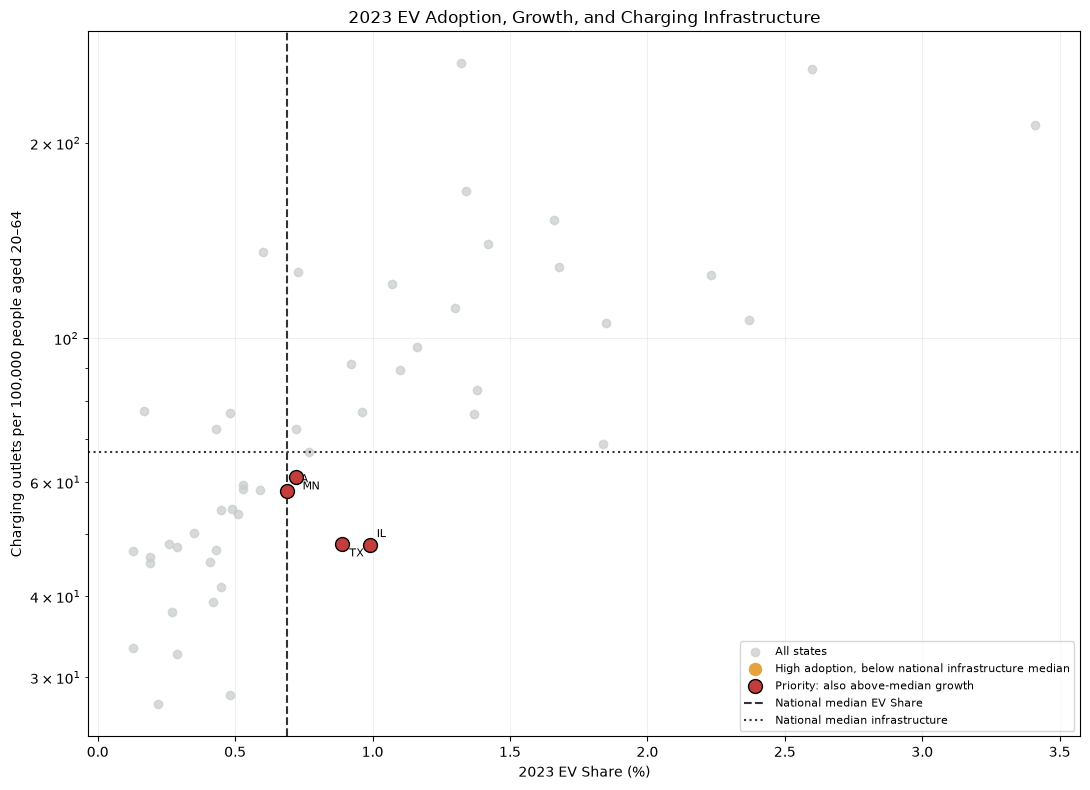

,state,EV Share (%),EV_Share_Change,Q1_Outlets_per_100k,Q1_Infrastructure_Gap_per_100k
13,Illinois,0.99,0.32,47.94,18.84
43,Texas,0.89,0.30,48.19,18.59
38,Pennsylvania,0.69,0.22,58.23,8.54
23,Minnesota,0.72,0.24,61.11,5.66


In [383]:
# Q1: Compare 2023 adoption and charging infrastructure with national medians.
# Growth is the observed 2022-to-2023 label, not the model's prediction.

q1_states_2023 = model_df.loc[
    model_df["year"].eq(2023),
    [
        "state",
        "state_code",
        "EV Share (%)",
        "EV Registrations",
        "Total Charging Outlets",
        "Population_20_64",
    ],
].copy()

q1_states_2023["Q1_Outlets_per_100k"] = (
    q1_states_2023["Total Charging Outlets"]
    / q1_states_2023["Population_20_64"]
    * 100_000
)

q1_growth_2022 = df_class.loc[
    df_class["year"].eq(2022),
    ["state", "EV_Share_Change", "High_EV_Growth"],
].copy()

q1_analysis = q1_states_2023.merge(
    q1_growth_2022,
    on="state",
    how="inner",
    validate="one_to_one",
)

q1_adoption_median = q1_analysis["EV Share (%)"].median()
q1_infrastructure_median = q1_analysis["Q1_Outlets_per_100k"].median()

q1_analysis["Q1_High_Adoption"] = (
    q1_analysis["EV Share (%)"] >= q1_adoption_median
)
q1_analysis["Q1_Below_National_Infrastructure"] = (
    q1_analysis["Q1_Outlets_per_100k"] < q1_infrastructure_median
)
q1_analysis["Q1_Infrastructure_Gap_per_100k"] = (
    q1_infrastructure_median - q1_analysis["Q1_Outlets_per_100k"]
).clip(lower=0)

q1_analysis["Q1_High_Adoption_Low_Infrastructure"] = (
    q1_analysis["Q1_High_Adoption"]
    & q1_analysis["Q1_Below_National_Infrastructure"]
)
q1_analysis["Q1_Priority_State"] = (
    q1_analysis["Q1_High_Adoption_Low_Infrastructure"]
    & q1_analysis["High_EV_Growth"].eq(1)
)

q1_candidates = q1_analysis.loc[
    q1_analysis["Q1_High_Adoption_Low_Infrastructure"]
].copy()
q1_priority_states = q1_analysis.loc[
    q1_analysis["Q1_Priority_State"]
].sort_values("Q1_Infrastructure_Gap_per_100k", ascending=False)

print(f"National median EV Share: {q1_adoption_median:.2f}%")
print(
    "National median charging infrastructure: "
    f"{q1_infrastructure_median:.1f} outlets per 100,000 people aged 20–64"
)
print(f"High-adoption states below the infrastructure median: {len(q1_candidates)}")
print(f"Priority states, including above-median growth: {len(q1_priority_states)}")

fig, ax = plt.subplots(figsize=(11, 8))

# Show every state, then overlay the candidate and priority groups.
ax.scatter(
    q1_analysis["EV Share (%)"],
    q1_analysis["Q1_Outlets_per_100k"],
    color="#C9CECC",
    alpha=0.75,
    label="All states",
)
ax.scatter(
    q1_candidates["EV Share (%)"],
    q1_candidates["Q1_Outlets_per_100k"],
    color="#E6A23C",
    s=75,
    label="High adoption, below national infrastructure median",
    zorder=3,
)
ax.scatter(
    q1_priority_states["EV Share (%)"],
    q1_priority_states["Q1_Outlets_per_100k"],
    color="#C43D3D",
    edgecolor="black",
    s=100,
    label="Priority: also above-median growth",
    zorder=4,
)

ax.axvline(
    q1_adoption_median,
    color="#333333",
    linestyle="--",
    label="National median EV Share",
)
ax.axhline(
    q1_infrastructure_median,
    color="#333333",
    linestyle=":",
    label="National median infrastructure",
)

# Label all high-adoption states below the national infrastructure median.
for position, (_, row) in enumerate(q1_candidates.iterrows()):
    offset_y = 6 if position % 2 == 0 else -9
    ax.annotate(
        row["state_code"],
        (row["EV Share (%)"], row["Q1_Outlets_per_100k"]),
        xytext=(5, offset_y),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_xlabel("2023 EV Share (%)")
ax.set_ylabel("Charging outlets per 100,000 people aged 20–64")
ax.set_title("2023 EV Adoption, Growth, and Charging Infrastructure")
ax.legend(fontsize=8)
ax.set_yscale("log")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(
    q1_priority_states[
        [
            "state",
            "EV Share (%)",
            "EV_Share_Change",
            "Q1_Outlets_per_100k",
            "Q1_Infrastructure_Gap_per_100k",
        ]
    ].round(2)
)

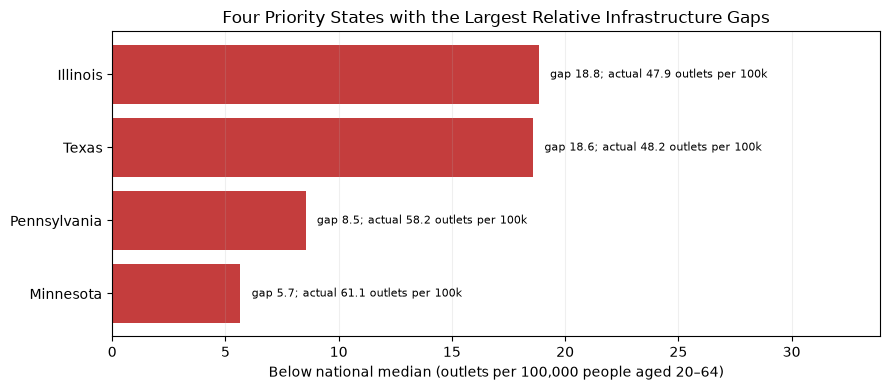

In [384]:
q1_top_states = q1_priority_states.head(4).sort_values(
    "Q1_Infrastructure_Gap_per_100k"
)

if q1_top_states.empty:
    print("No states meet all three Q1 priority criteria.")
else:
    fig, ax = plt.subplots(figsize=(9, max(4, 0.8 * len(q1_top_states))))

    bars = ax.barh(
        q1_top_states["state"],
        q1_top_states["Q1_Infrastructure_Gap_per_100k"],
        color="#C43D3D",
    )

    for bar, (_, row) in zip(bars, q1_top_states.iterrows()):
        ax.text(
            bar.get_width() + 0.5,
            bar.get_y() + bar.get_height() / 2,
            (
                f"gap {row['Q1_Infrastructure_Gap_per_100k']:.1f}; "
                f"actual {row['Q1_Outlets_per_100k']:.1f} outlets per 100k"
            ),
            va="center",
            fontsize=8,
        )

    ax.set_xlim(
        0,
        q1_top_states["Q1_Infrastructure_Gap_per_100k"].max() * 1.8,
    )
    ax.set_xlabel(
        "Below national median (outlets per 100,000 people aged 20–64)"
    )
    ax.set_title("Four Priority States with the Largest Relative Infrastructure Gaps")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

Using the national medians as benchmarks, four states meet our priority criteria: high 2023 EV adoption, above-median growth from 2022 to 2023, and charging-outlet availability below the national median.

 Illinois and Texas have the largest relative infrastructure gaps, at about 18.8 and 18.6 fewer outlets per 100,000 adults aged 20–64 than the national median. Pennsylvania’s gap is about 8.5, and Minnesota’s is about 5.7.

The comparison is statewide and does not account for charger locations, capacity, or local demand.

### Q2. How much charging infrastructure pressure do the priority states experience relative to other high-adoption states?

This converts the per-capita shortfall into an approximate number of outlets needed to reach the peer benchmark. It’s a benchmark comparison, not an estimate of actual need.

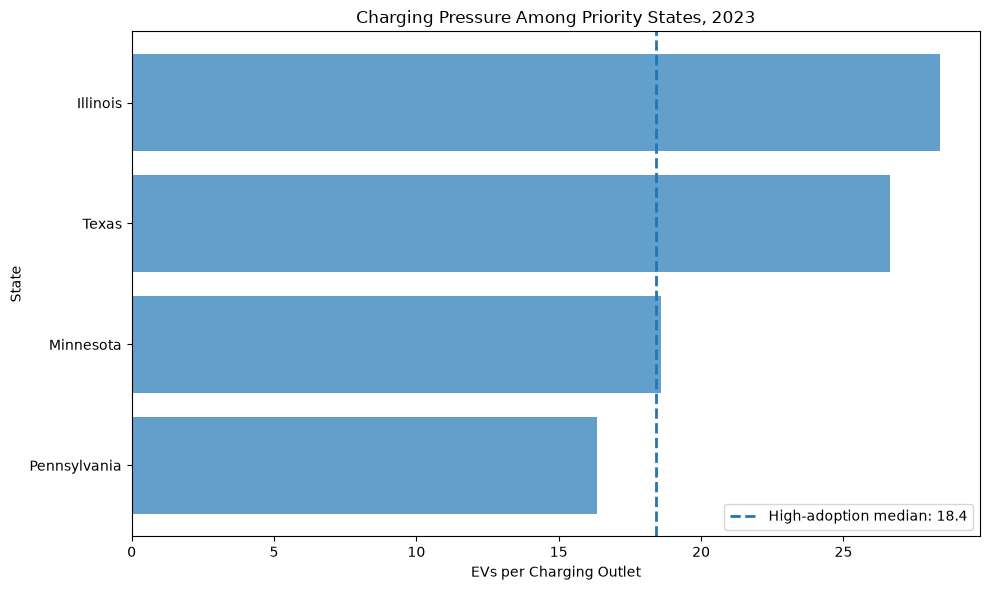

In [389]:
# EV pressure: EVs served per charging outlet
state_analysis["EVs_per_Outlet"] = (
    state_analysis["EV Registrations"]
    / state_analysis["Total Charging Outlets"]
)

# Benchmark among high-adoption states
ev_pressure_benchmark = state_analysis.loc[
    state_analysis["High_Adoption"],
    "EVs_per_Outlet"
].median()

# Pressure relative to benchmark
state_analysis["EV_Pressure_Gap"] = (
    state_analysis["EVs_per_Outlet"]
    - ev_pressure_benchmark
)

plot_data = state_analysis.loc[
    state_analysis["Priority_State"]
].sort_values(
    "EVs_per_Outlet",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["state"],
    plot_data["EVs_per_Outlet"],
    alpha=0.7
)

ax.axvline(
    ev_pressure_benchmark,
    linestyle="--",
    linewidth=2,
    label=f"High-adoption median: {ev_pressure_benchmark:.1f}"
)

ax.set_xlabel("EVs per Charging Outlet")
ax.set_ylabel("State")
ax.set_title(
    "Charging Pressure Among Priority States, 2023"
)

ax.legend()
plt.tight_layout()
plt.show()

Illinois and Texas experience the greatest charging pressure among the priority states, with roughly 27–28 EVs per charging outlet compared with the high-adoption median of 18.4. Minnesota is approximately at the peer benchmark, while Pennsylvania falls below it. This suggests that the infrastructure gap identified in Q1 translates into particularly high EV demand per outlet in Illinois and Texas.

This distinction matters because having fewer charging outlets does not necessarily mean a state is experiencing the greatest demand pressure. Q2 shows which priority states have the most EVs competing for each outlet, helping us determine where the infrastructure gap may be most consequential.

### Q3. Which outlet types are comparatively low?

Compare each priority state’s Level 1, Level 2, and DC Fast outlet density with the corresponding median among all high-adoption states.

,Priority states,Other high-adoption states,National median
Level 1,0.7,2.7,0.8
Level 2,39.6,93.8,45.8
DC Fast,13.3,20.6,15.5


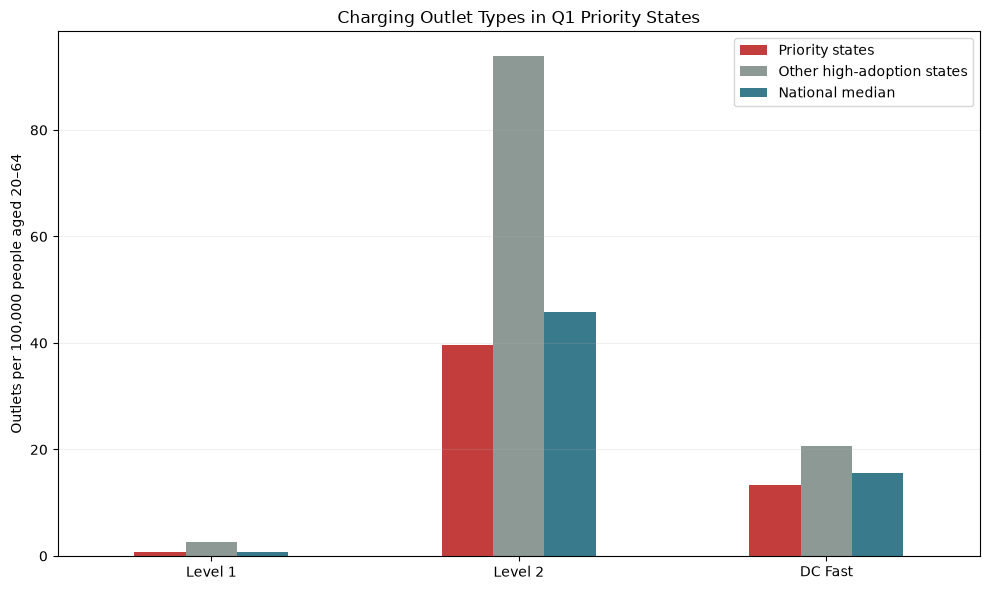

In [393]:
# Add 2023 outlet-type counts to the Q1 analysis table.
q3_components = model_df.loc[
    model_df["year"].eq(2023),
    ["state", "Level 1", "Level 2", "DC Fast"],
].copy()

q3_analysis = q1_analysis.merge(
    q3_components,
    on="state",
    how="left",
    validate="one_to_one",
)

# Express each outlet type using the same population denominator as Q1.
q3_types = {
    "Level 1": "Q3_Level1_per_100k",
    "Level 2": "Q3_Level2_per_100k",
    "DC Fast": "Q3_DCFast_per_100k",
}

for source_column, density_column in q3_types.items():
    q3_analysis[density_column] = (
        q3_analysis[source_column]
        / q3_analysis["Population_20_64"]
        * 100_000
    )

q3_priority = q3_analysis["Q1_Priority_State"]
q3_other_high_adoption = (
    q3_analysis["Q1_High_Adoption"]
    & ~q3_analysis["Q1_Priority_State"]
)

# Compare medians to reduce the influence of unusually large states.
q3_summary = pd.DataFrame({
    "Priority states": q3_analysis.loc[
        q3_priority, list(q3_types.values())
    ].median(),
    "Other high-adoption states": q3_analysis.loc[
        q3_other_high_adoption, list(q3_types.values())
    ].median(),
    "National median": q3_analysis[list(q3_types.values())].median(),
})

q3_summary.index = ["Level 1", "Level 2", "DC Fast"]
display(q3_summary.round(1))

ax = q3_summary[
    ["Priority states", "Other high-adoption states", "National median"]
].plot(
    kind="bar",
    figsize=(10, 6),
    color=["#C43D3D", "#8C9995", "#397A8C"],
)

ax.set_ylabel("Outlets per 100,000 people aged 20–64")
ax.set_xlabel("")
ax.set_title("Charging Outlet Types in Q1 Priority States")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Priority states have fewer charging outlets per 1,000 EVs than other high-adoption states across all three outlet types.

The largest difference is in Level 2 charging, where priority states have 39.6 outlets per 1,000 EVs compared with 93.8 among other high-adoption states. Level 1 and DC Fast charging also fall below the peer group, but the gap is smaller.

This suggests that Level 2 infrastructure represents the largest relative shortfall among priority states and may be the most important area for expansion.

### Q4. Is infrastructure keeping pace with EV adoption over time in the priority states?

In [398]:
q4_priority_names = set(q1_priority_states["state"])

q4_peer_names = set(
    q1_analysis.loc[
        q1_analysis["Q1_High_Adoption"]
        & ~q1_analysis["Q1_Priority_State"],
        "state",
    ]
)

q4_state_names = q4_priority_names | q4_peer_names

q4_data = model_df.loc[
    model_df["state"].isin(q4_state_names)
    & model_df["year"].between(2018, 2023)
].copy()

q4_data["Q4_Group"] = np.where(
    q4_data["state"].isin(q4_priority_names),
    "Q1 priority states",
    "Other high-adoption states",
)

In [399]:
q4_annual = (
    q4_data.groupby(["Q4_Group", "year"], as_index=False)
    .agg(
        EV_Registrations=("EV Registrations", "sum"),
        Charging_Outlets=("Total Charging Outlets", "sum"),
    )
    .sort_values(["Q4_Group", "year"])
)

q4_annual["EVs_per_Outlet"] = (
    q4_annual["EV_Registrations"]
    / q4_annual["Charging_Outlets"]
)

for measure in ["EV_Registrations", "Charging_Outlets"]:
    baseline = q4_annual.groupby("Q4_Group")[measure].transform("first")
    q4_annual[f"{measure}_Index"] = q4_annual[measure] / baseline * 100

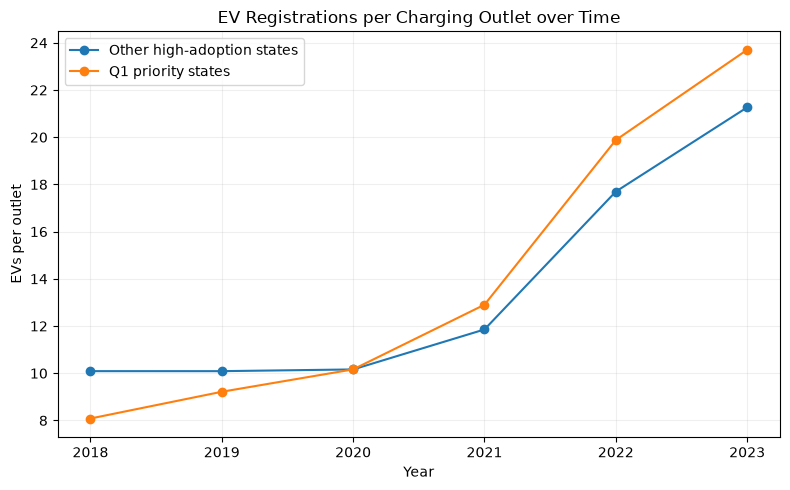

In [400]:
fig, ax = plt.subplots(figsize=(8, 5))

for group, subset in q4_annual.groupby("Q4_Group"):
    ax.plot(
        subset["year"],
        subset["EVs_per_Outlet"],
        marker="o",
        label=group,
    )

ax.set_title("EV Registrations per Charging Outlet over Time")
ax.set_xlabel("Year")
ax.set_ylabel("EVs per outlet")
ax.set_xticks(sorted(q4_annual["year"].unique()))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

EV registrations per charging outlet increased over time in both groups, indicating that EV adoption grew faster than charging infrastructure. The increase was more pronounced among priority states, suggesting that infrastructure has not kept pace with EV adoption as effectively in these states.

# 5. Key Recommendations


* Prioritize charging-infrastructure gap assessments.
    Our regression identified charging infrastructure, measured as outlets per 100,000 people, as one of the strongest contributors to EV Share predictions. We recommend that state transportation agencies identify areas with relatively low charging availability and assess whether additional public charging infrastructure is warranted.

* Use charging availability to guide infrastructure planning.
    Rather than evaluating charging infrastructure only at the statewide level, agencies can compare outlet availability across regions and identify communities that may be underserved relative to their population.

* Monitor gasoline-price and EV-adoption patterns when planning EV initiatives.
    Gasoline price was also among the stronger predictors in our regression. State agencies can incorporate gasoline and electricity price trends into EV-market monitoring to better understand how changing energy costs coincide with adoption patterns.


# 6. Notable Limitations

1. The dataset covers 2018–2023, limiting our ability to evaluate longer-term adoption trends or within-state changes over extended periods.

2. “Above-median growth” is a relative measure. A state can be classified as above median even when its absolute growth is modest, depending on how other states performed that year.